In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.io import arff
from scipy.spatial.distance import pdist, squareform

from sklearn.decomposition import PCA
from sklearn.manifold import MDS
from sklearn.metrics import silhouette_score
from sklearn.metrics import silhouette_samples

import umap
from itertools import combinations


# Reducción dimensional - WISDM

## 1. Configuración

In [41]:
base_path = (
    "/Users/franche/Downloads/wisdm+smartphone+and+smartwatch+activity+and+biometrics+dataset/wisdm-dataset/arff_files"
)

cases = {
    "phone_accel": ("phone", "accel"),
    "phone_gyro": ("phone", "gyro"),
    "watch_accel": ("watch", "accel"),
    "watch_gyro": ("watch", "gyro")
}

activity_map = {
    "A": "walking",
    "B": "jogging",
    "C": "stairs",
    "D": "sitting",
    "E": "standing",
    "F": "typing",
    "G": "teeth",
    "H": "soup",
    "I": "chips",
    "J": "pasta",
    "K": "drinking",
    "L": "sandwich",
    "M": "kicking",
    "O": "catch",
    "P": "dribbling",
    "Q": "writing",
    "R": "clapping",
    "S": "folding"
}

xyzbins = (
    [f"X{i}" for i in range(10)] +
    [f"Y{i}" for i in range(10)] +
    [f"Z{i}" for i in range(10)]
)

In [42]:
def load_arff(path):
    data, metadata = arff.loadarff(path)
    df = pd.DataFrame(data)
    df.columns = df.columns.str.replace('"', '', regex=False)
    
    return df




In [43]:
def load_subject(subject_id, device, sensor):
    path = (
        f"{base_path}/{device}/{sensor}/"
        f"data_{subject_id}_{sensor}_{device}.arff"
    )
    
    return load_arff(path)

In [44]:
def prepare_subject(subject_id, device, sensor):
    df = load_subject(subject_id, device, sensor)
    
    X = df[xyzbins]
    y = df["ACTIVITY"]
    
    if isinstance(y.iloc[0], bytes):
        y = y.str.decode("utf-8")
    
    return X, y

## 2. Selección de voluntarios

In [46]:
subjects = [i for i in range(1600, 1651) if i != 1614]

rng = np.random.default_rng(42)
selected_subjects = rng.choice(subjects, size=3, replace=False)

print(selected_subjects)

[1633 1604 1638]


## 3. Reducción Dimensional 

In [47]:
def plot_embedding(X_reduced, y, title, xlabel="Component 1", ylabel="Component 2"):
    activities = list(activity_map.values())
    
    cmap = plt.get_cmap("tab20")
    
    plt.figure(figsize=(10, 7))
    
    for i, activity in enumerate(activities):
        mask = y == activity
        
        if mask.sum() == 0:
            continue
        
        plt.scatter(
            X_reduced[mask, 0],
            X_reduced[mask, 1],
            label=activity,
            color=cmap(i),
            alpha=0.7
        )
    
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

In [48]:
methods = [
    "pca",
    "classical_mds",
    "metric_mds",
    "nonmetric_mds",
    "umap"
]

In [49]:
def reduce_dimensions(X, method):
    
    if method == "pca":
        model = PCA(n_components=2)
        X_reduced = model.fit_transform(X)
        
        info = {
            "explained_variance": model.explained_variance_ratio_.sum()
        }
        
    elif method == "classical_mds":
        # Matriz de distancias
        distances = squareform(pdist(X))
        
        # Matriz de centrado
        n = X.shape[0]
        J = np.eye(n) - np.ones((n, n)) / n
        
        # Matriz B
        B = -0.5 * J @ (distances ** 2) @ J
        
        # Descomposición espectral
        eigenvalues, eigenvectors = np.linalg.eigh(B)
        
        # Seleccionar los dos mayores autovalores positivos
        positive = eigenvalues > 0
        eigenvalues_positive = eigenvalues[positive]
        eigenvectors_positive = eigenvectors[:, positive]
        
        indices = np.argsort(eigenvalues_positive)[::-1][:2]
        
        top_eigenvalues = eigenvalues_positive[indices]
        top_eigenvectors = eigenvectors_positive[:, indices]
        
        # Coordenadas 2D
        X_reduced = (
            top_eigenvectors
            @ np.diag(np.sqrt(top_eigenvalues))
        )
        
        info = {
            "eigenvalues": top_eigenvalues
        }
        
    elif method == "metric_mds":
        model = MDS(
            n_components=2,
            metric_mds=True,
            init="random",
            random_state=42
        )
        
        X_reduced = model.fit_transform(X)
        
        info = {
            "stress": model.stress_
        }
        
    elif method == "nonmetric_mds":
        model = MDS(
            n_components=2,
            metric_mds=False,
            init="random",
            random_state=42
        )
        
        X_reduced = model.fit_transform(X)
        
        info = {
            "stress": model.stress_
        }
        
    elif method == "umap":
        model = umap.UMAP(
            n_components=2,
            random_state=42
        )
        
        X_reduced = model.fit_transform(X)
        
        info = {}
        
    else:
        raise ValueError(f"Método no reconocido: {method}")
    
    return X_reduced, info

## 4. Análisis Individual

In [50]:
def analyze_subject(subject_id, case_name):
    
    device, sensor = cases[case_name]
    
    # Cargar datos
    X, y = prepare_subject(subject_id, device, sensor)
    
    # Convertir códigos de actividad a nombres
    y_names = y.map(activity_map)
    
    results = {}
    
    print(f"\nVoluntario: {subject_id}")
    print(f"Caso: {case_name}")
    print(f"Datos: {X.shape}")
    
    for method in methods:
        
        print(f"  Ejecutando {method}...")
        
        X_reduced, info = reduce_dimensions(X, method)
        
        results[method] = {
            "X_reduced": X_reduced,
            "info": info
        }
        
        plot_embedding(
            X_reduced,
            y_names,
            title=f"{method} - Voluntario {subject_id} - {case_name}"
        )
    
    return results


Voluntario: 1633
Caso: phone_accel
Datos: (429, 30)
  Ejecutando pca...


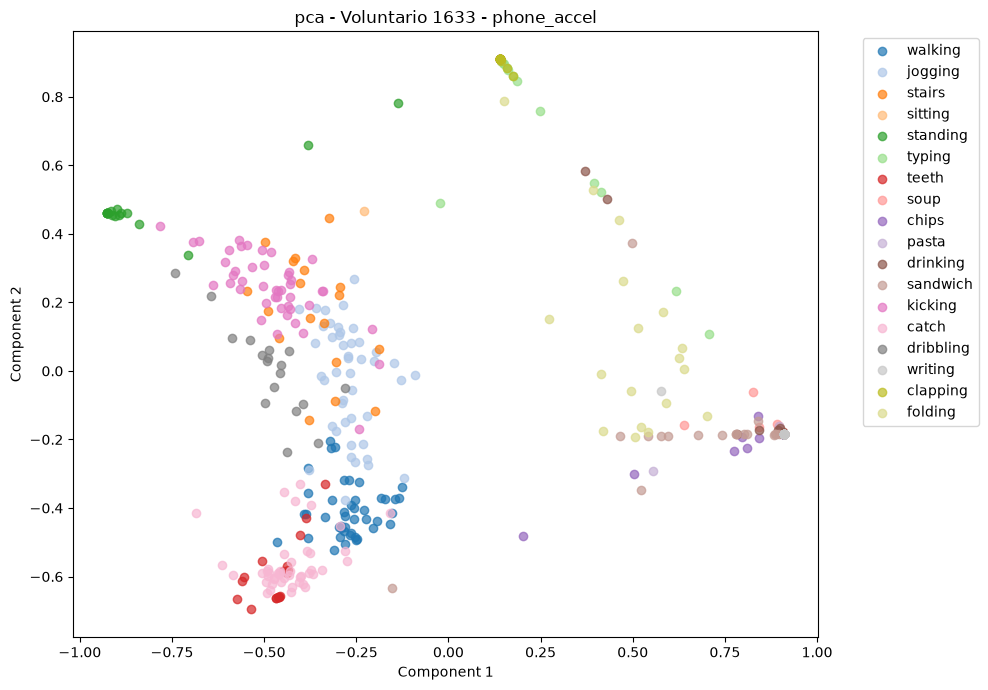

  Ejecutando classical_mds...


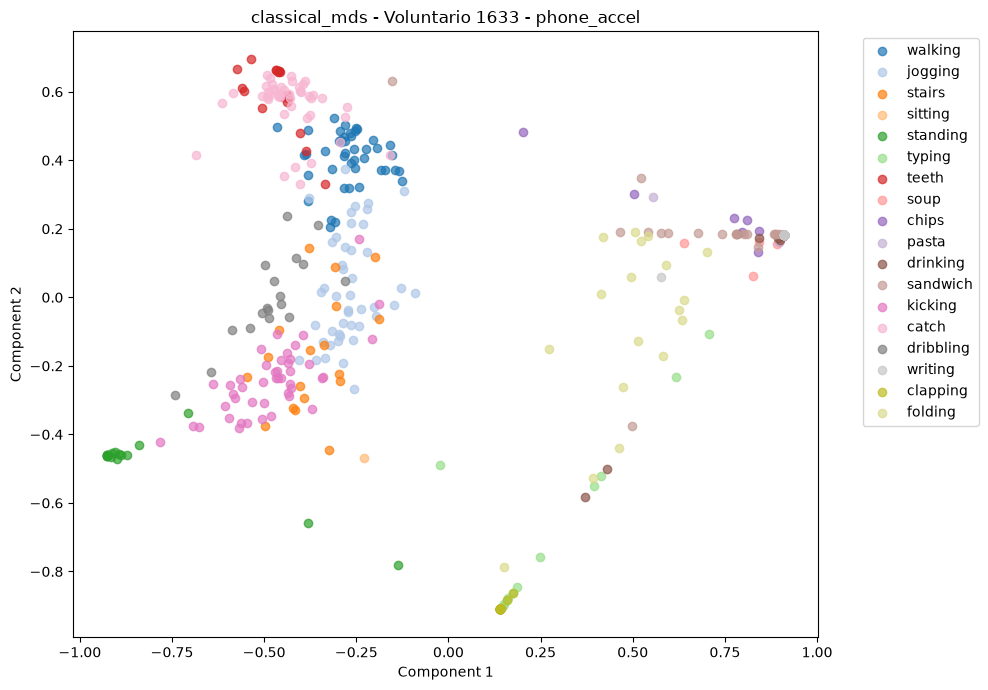

  Ejecutando metric_mds...


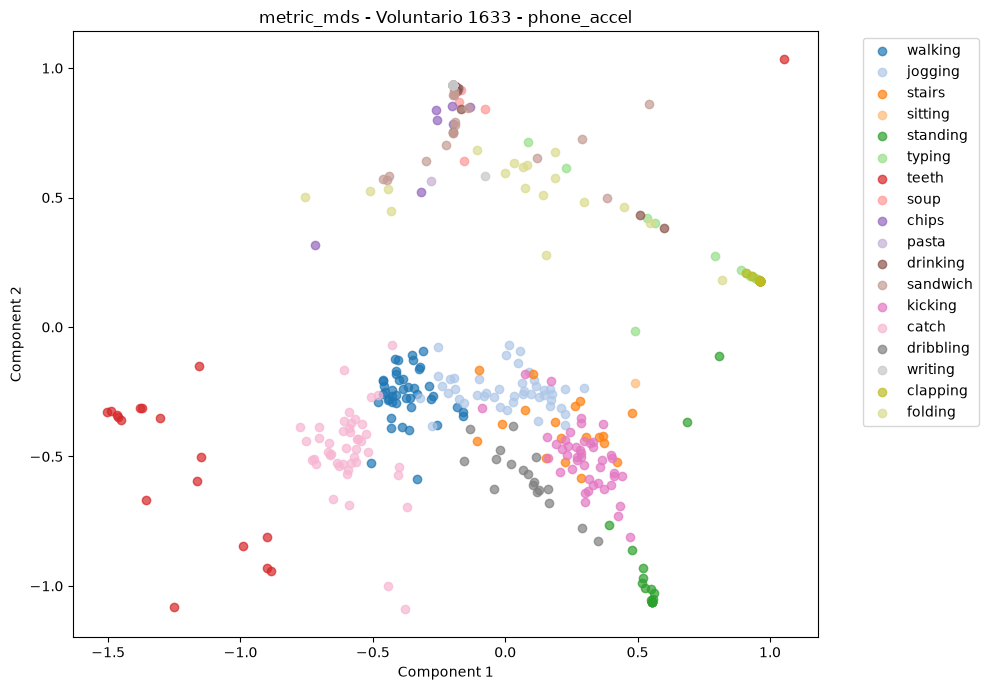

  Ejecutando nonmetric_mds...


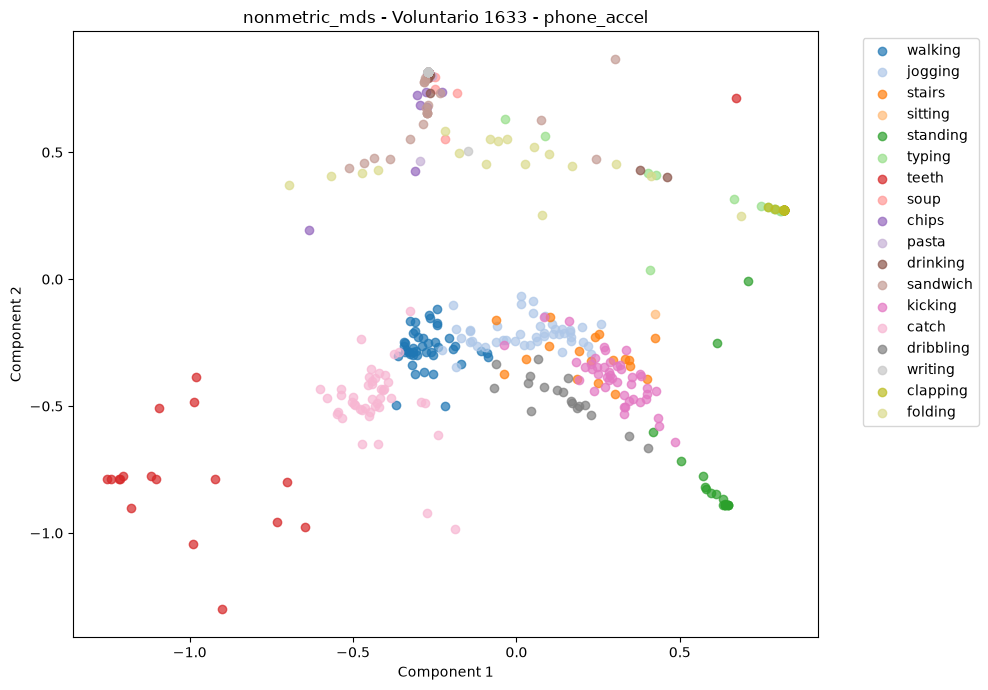

  Ejecutando umap...


/Users/franche/coding/Talleres_IA/Taller_06-Reducción/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


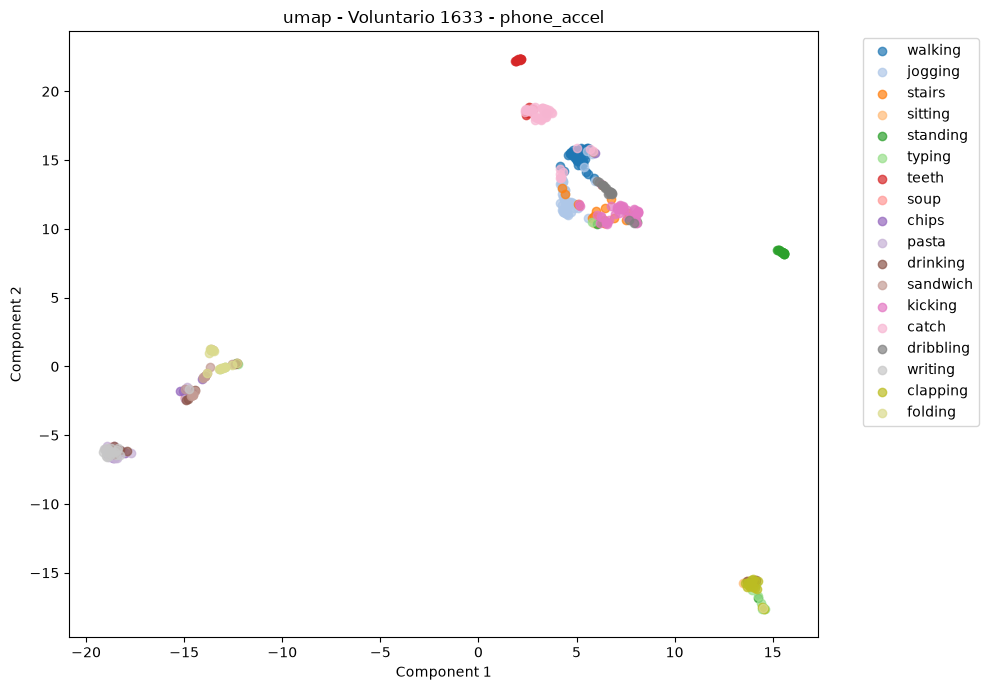


Voluntario: 1633
Caso: phone_gyro
Datos: (321, 30)
  Ejecutando pca...


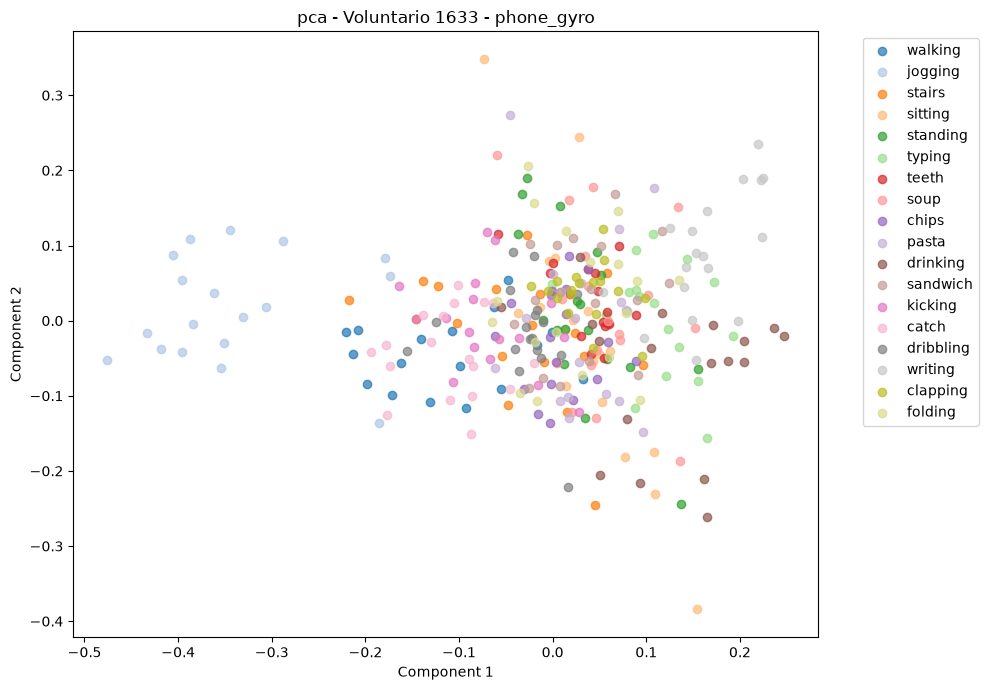

  Ejecutando classical_mds...


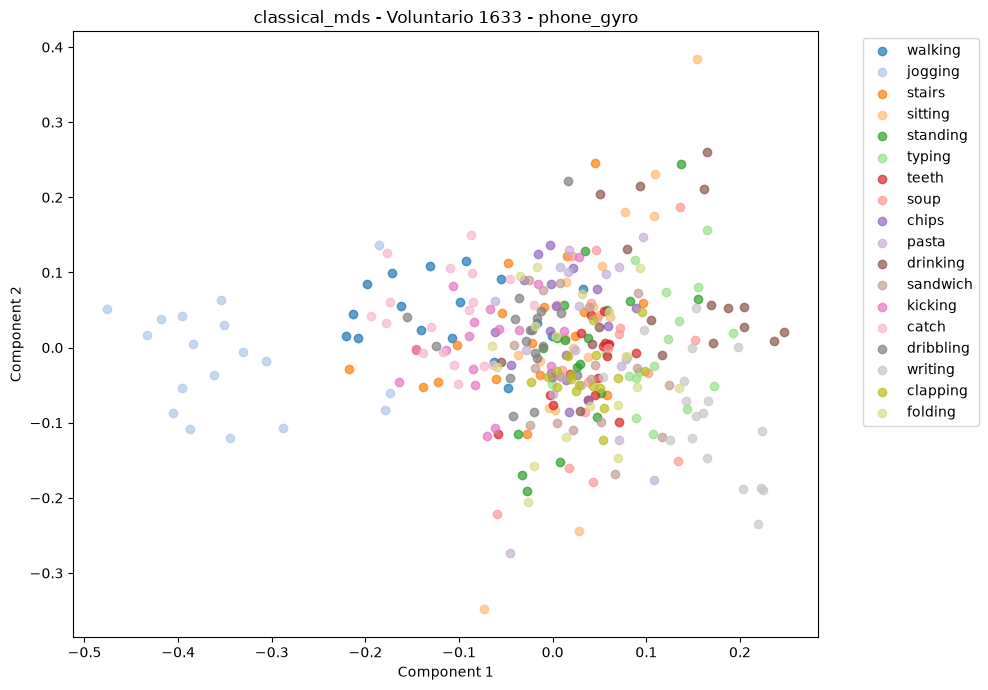

  Ejecutando metric_mds...


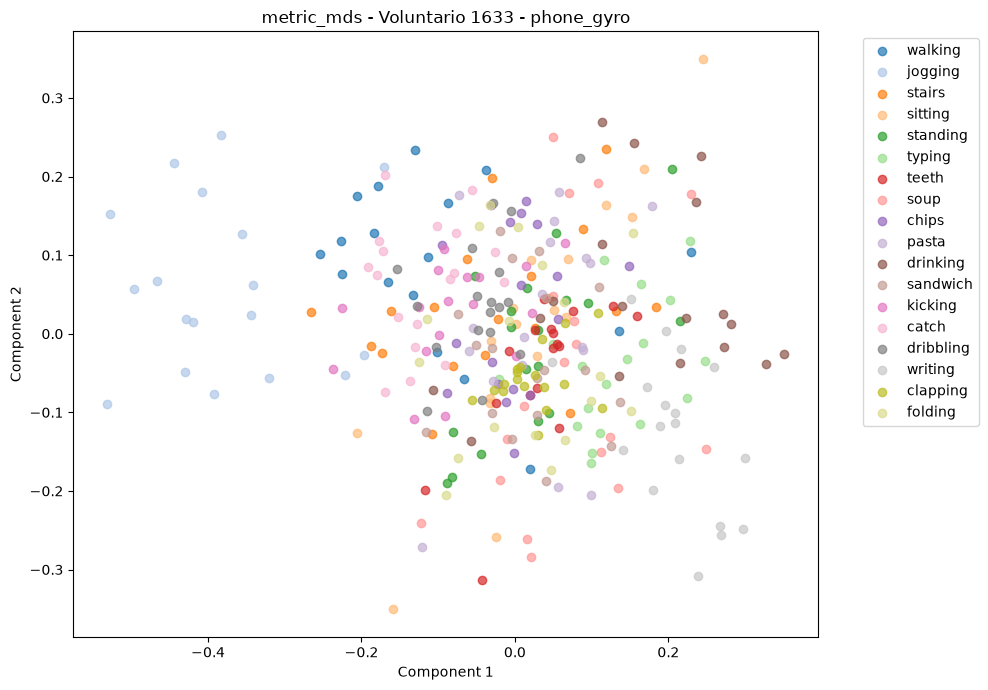

  Ejecutando nonmetric_mds...


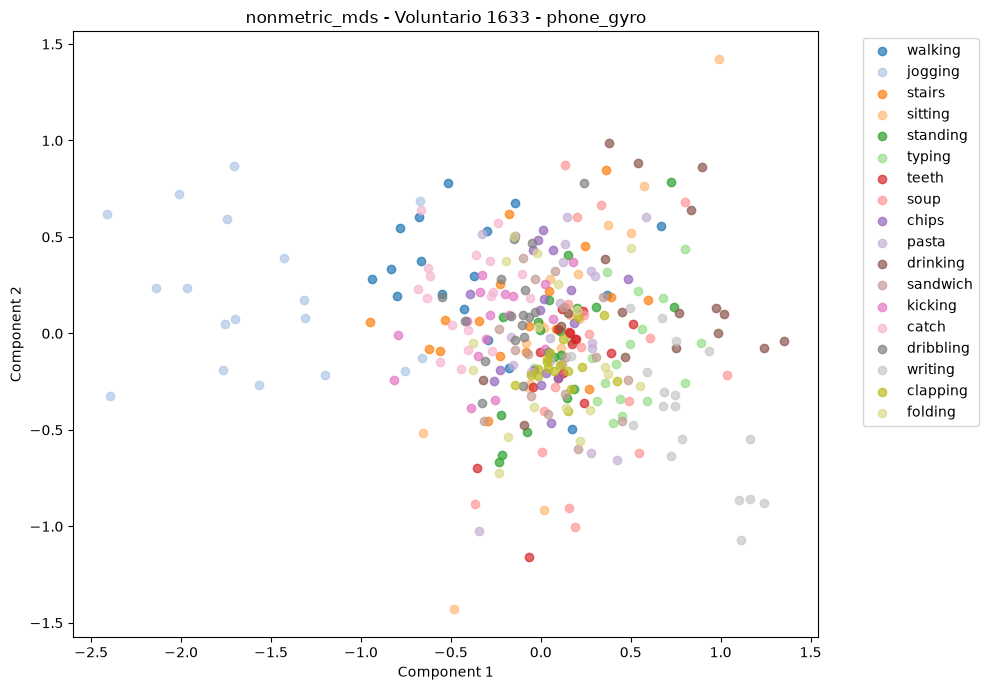

  Ejecutando umap...


/Users/franche/coding/Talleres_IA/Taller_06-Reducción/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


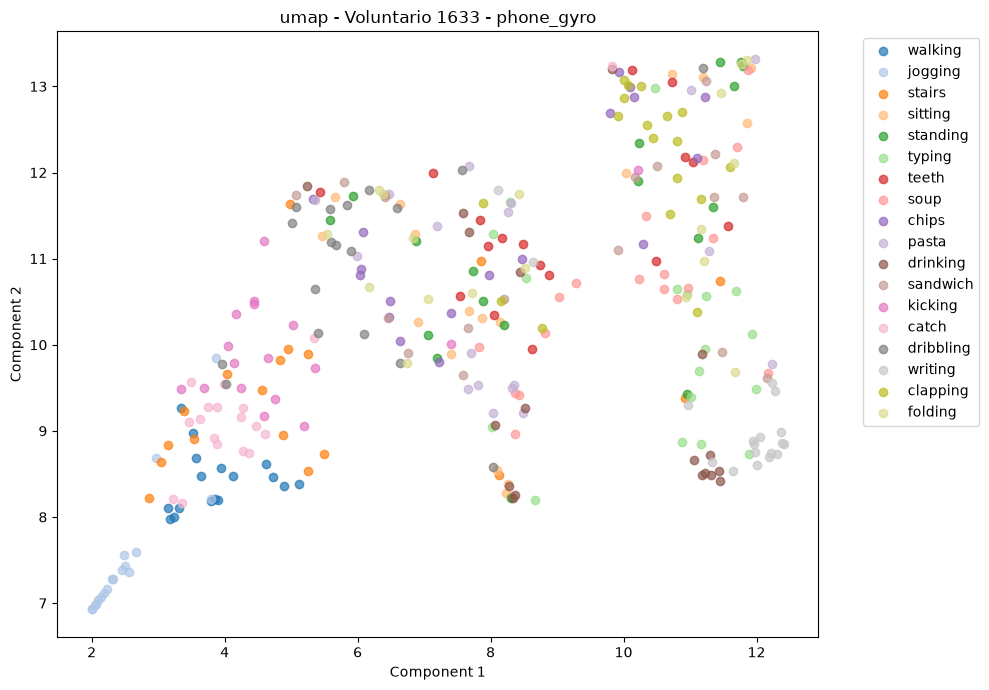


Voluntario: 1633
Caso: watch_accel
Datos: (324, 30)
  Ejecutando pca...


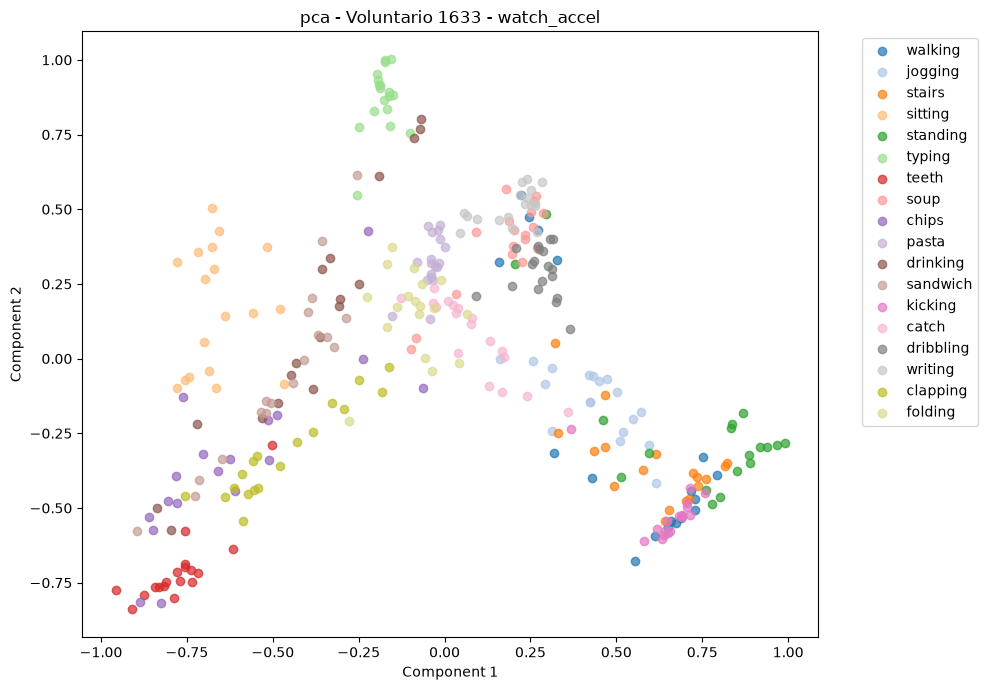

  Ejecutando classical_mds...


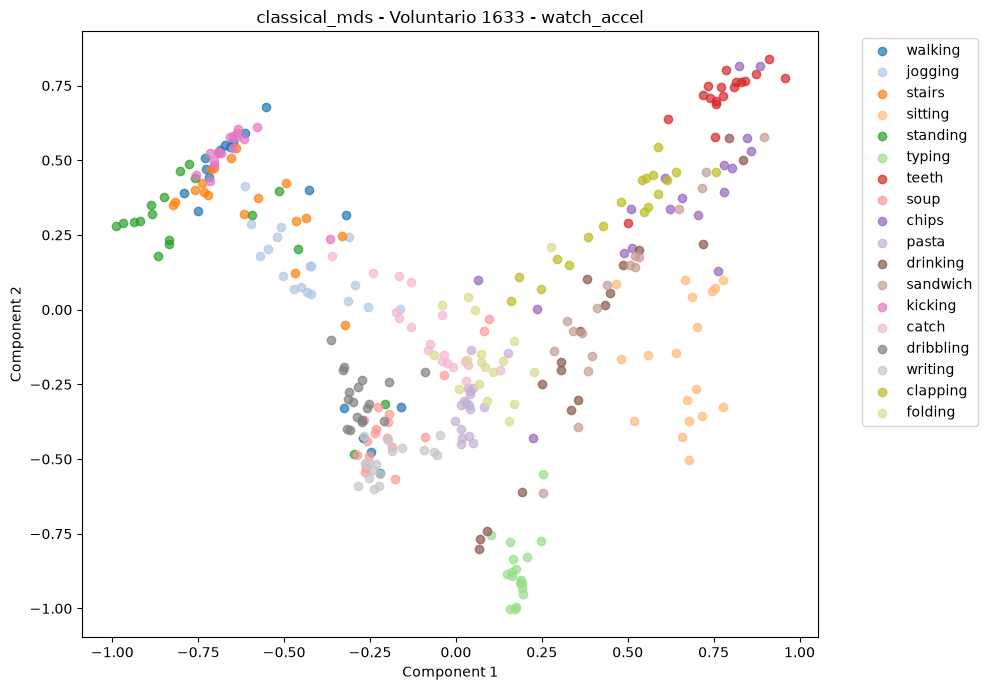

  Ejecutando metric_mds...


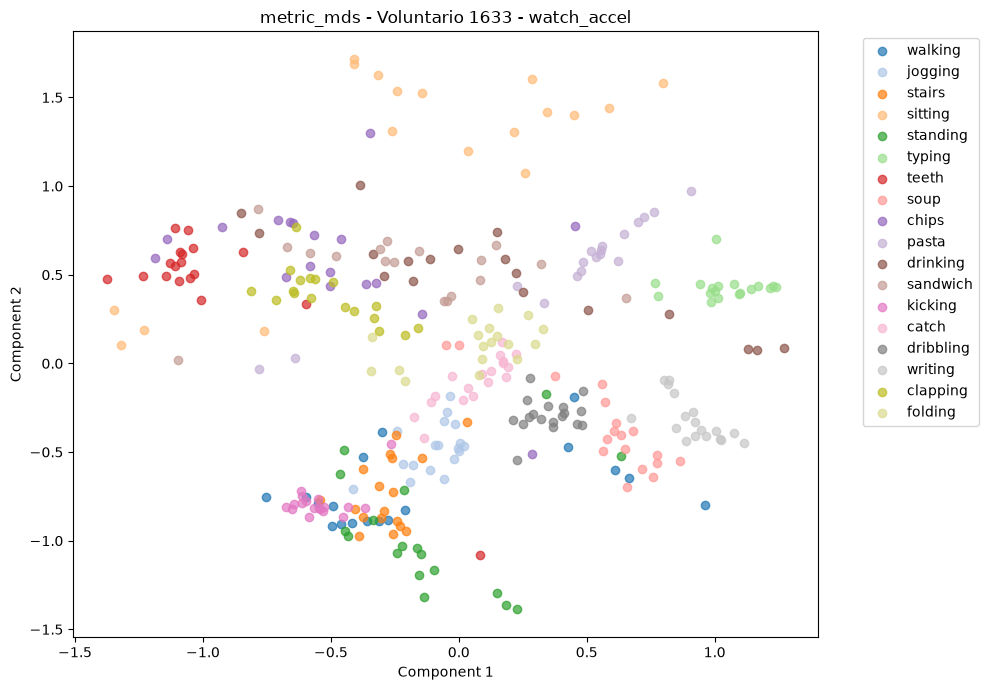

  Ejecutando nonmetric_mds...


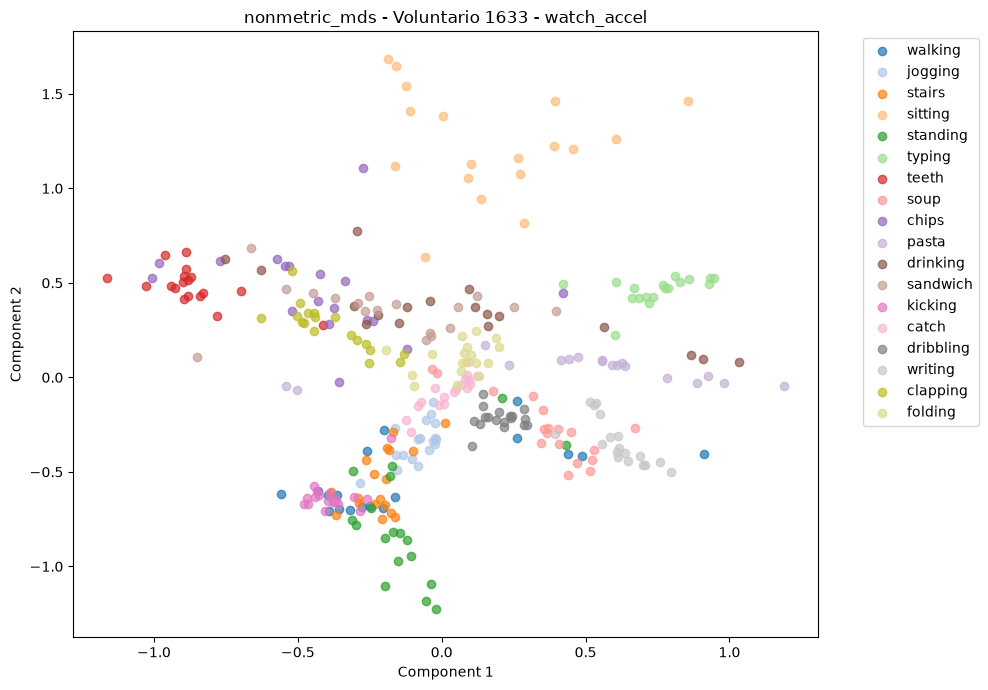

  Ejecutando umap...


/Users/franche/coding/Talleres_IA/Taller_06-Reducción/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


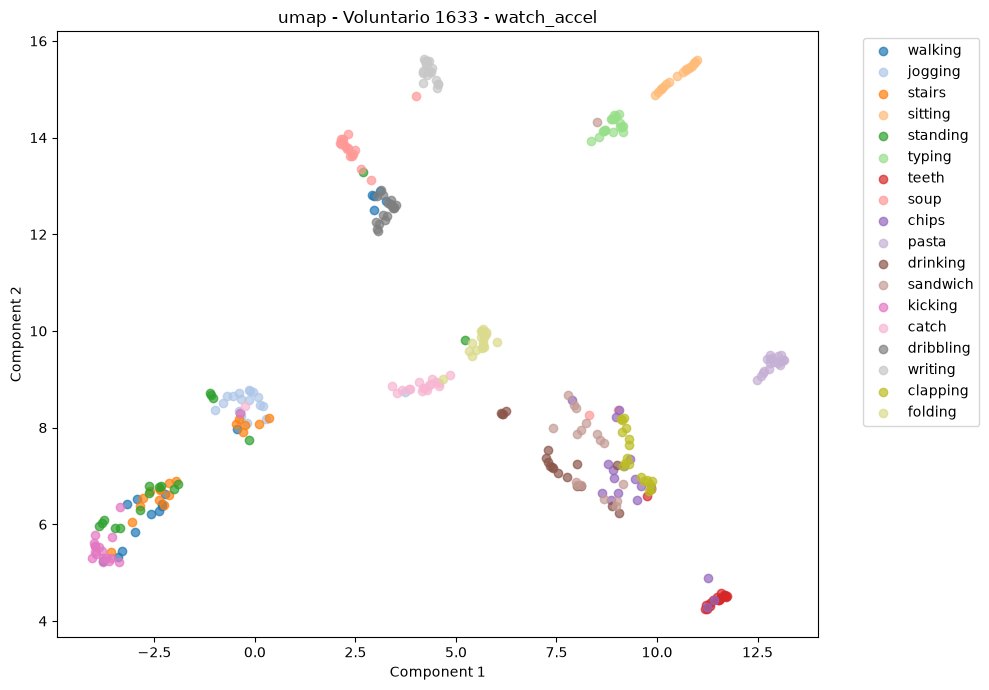


Voluntario: 1633
Caso: watch_gyro
Datos: (324, 30)
  Ejecutando pca...


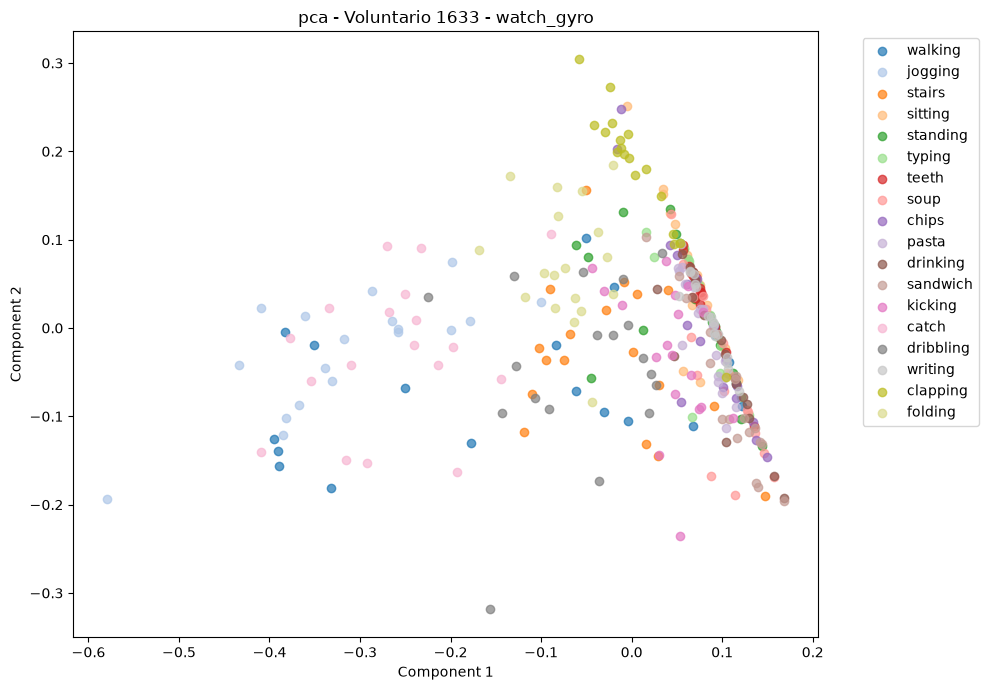

  Ejecutando classical_mds...


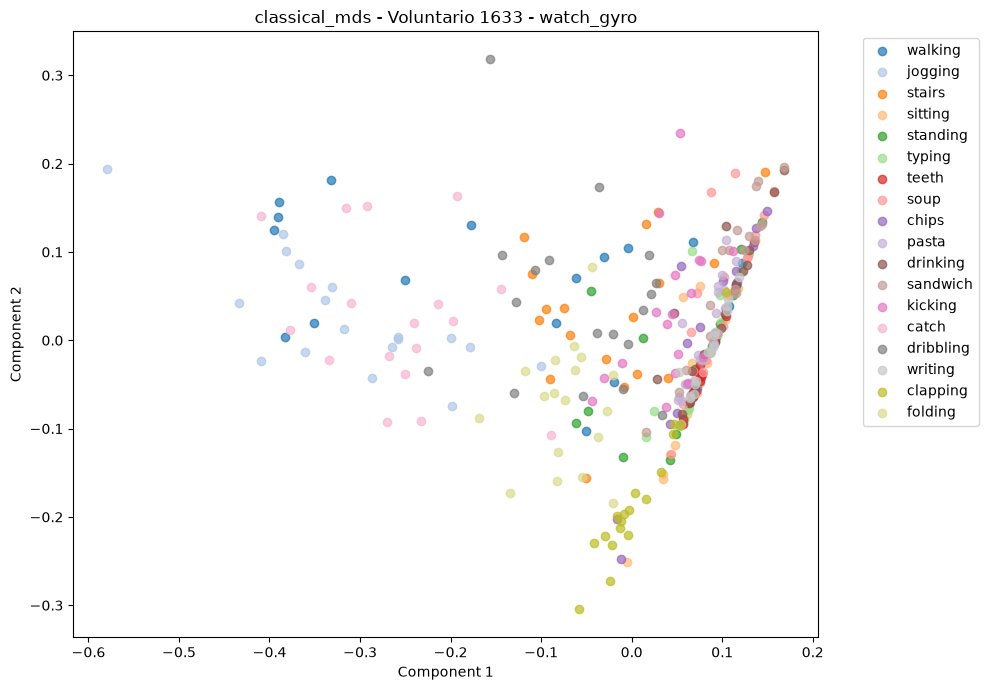

  Ejecutando metric_mds...


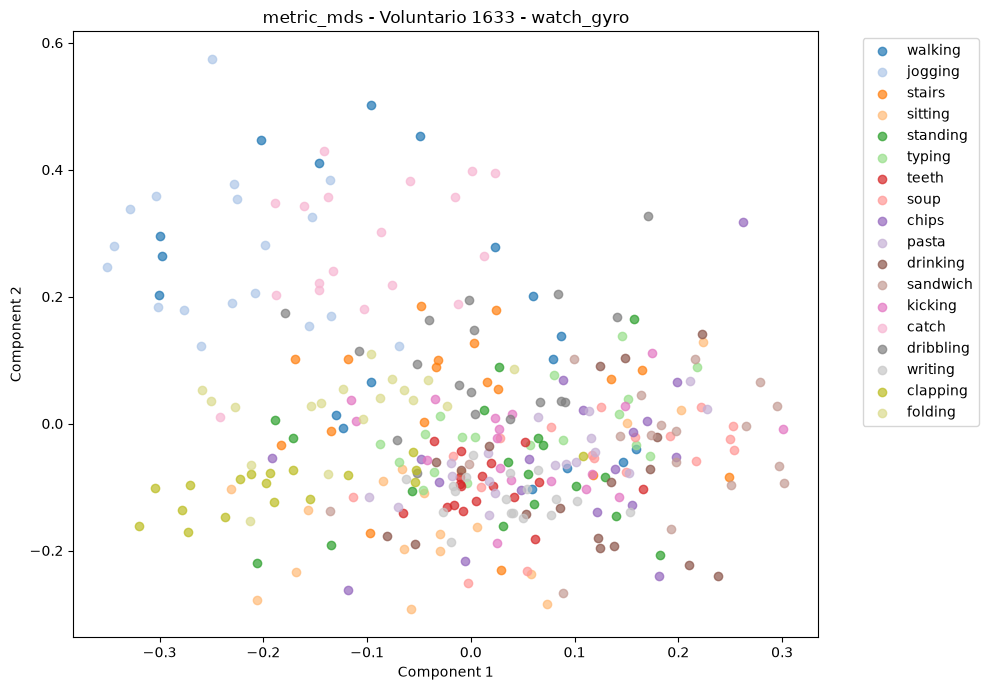

  Ejecutando nonmetric_mds...


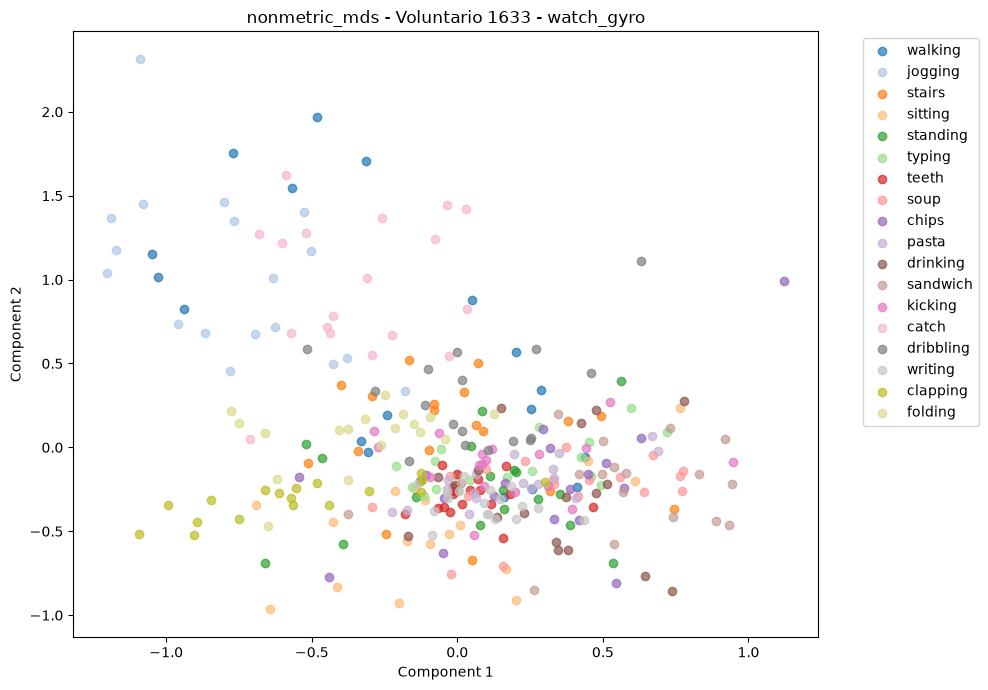

  Ejecutando umap...


/Users/franche/coding/Talleres_IA/Taller_06-Reducción/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


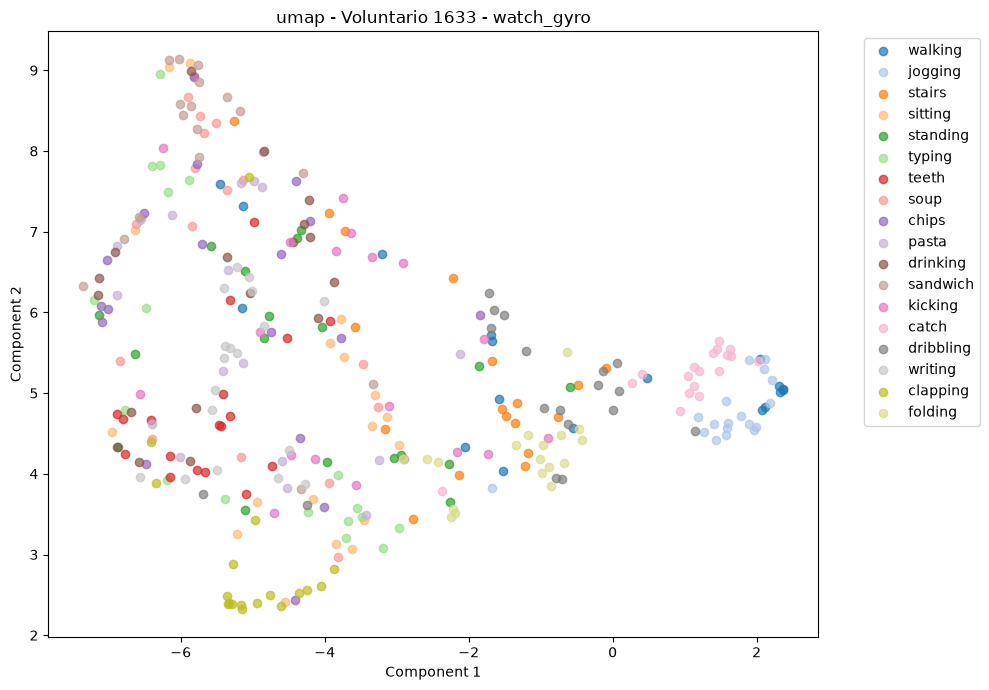


Voluntario: 1604
Caso: phone_accel
Datos: (321, 30)
  Ejecutando pca...


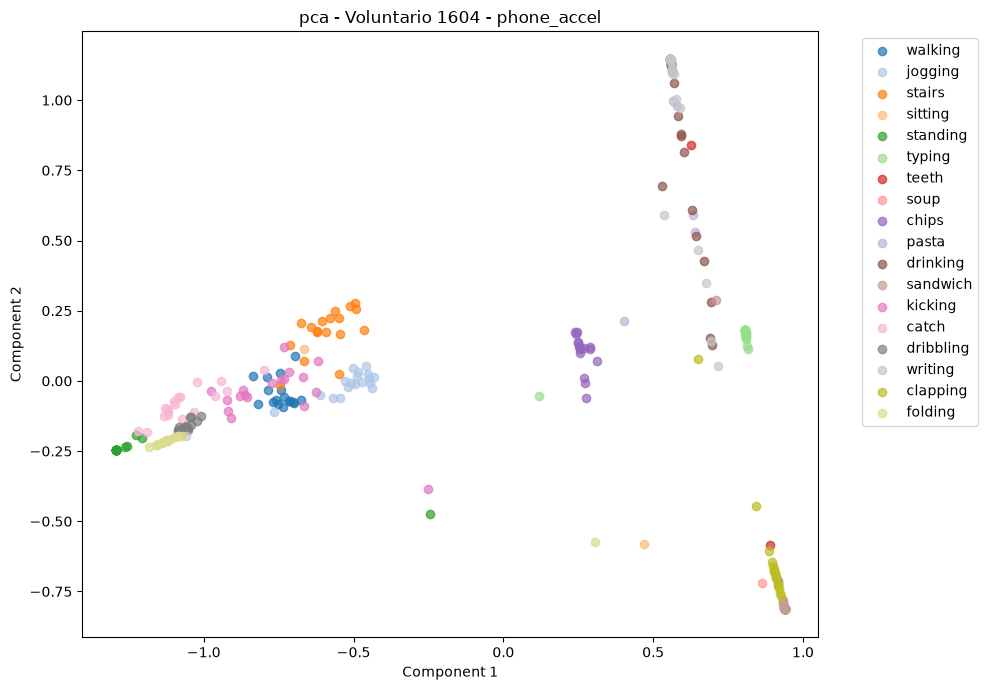

  Ejecutando classical_mds...


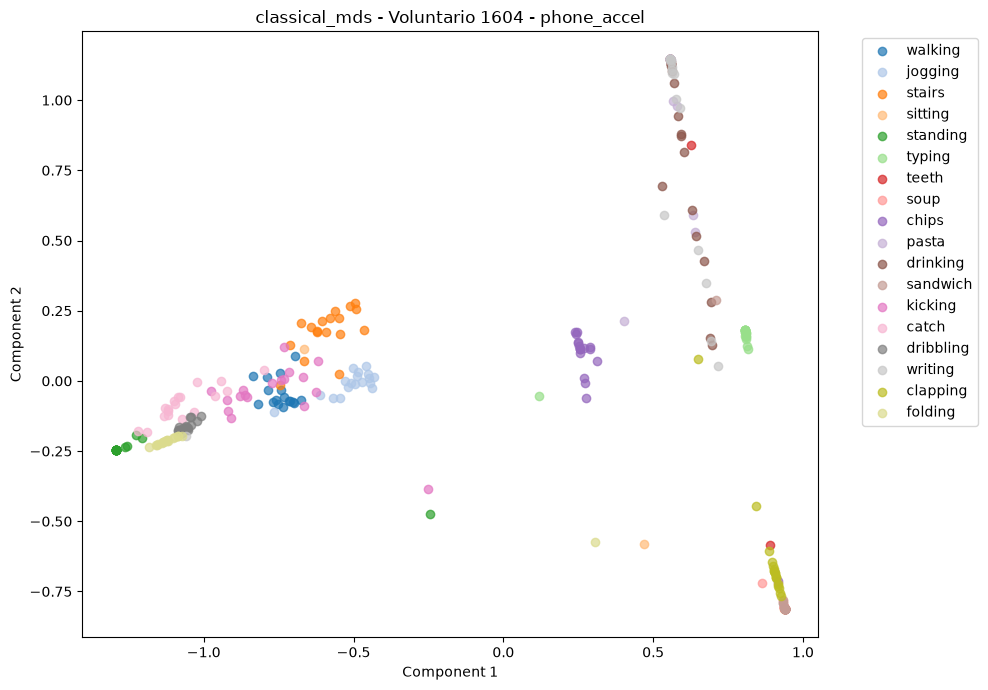

  Ejecutando metric_mds...


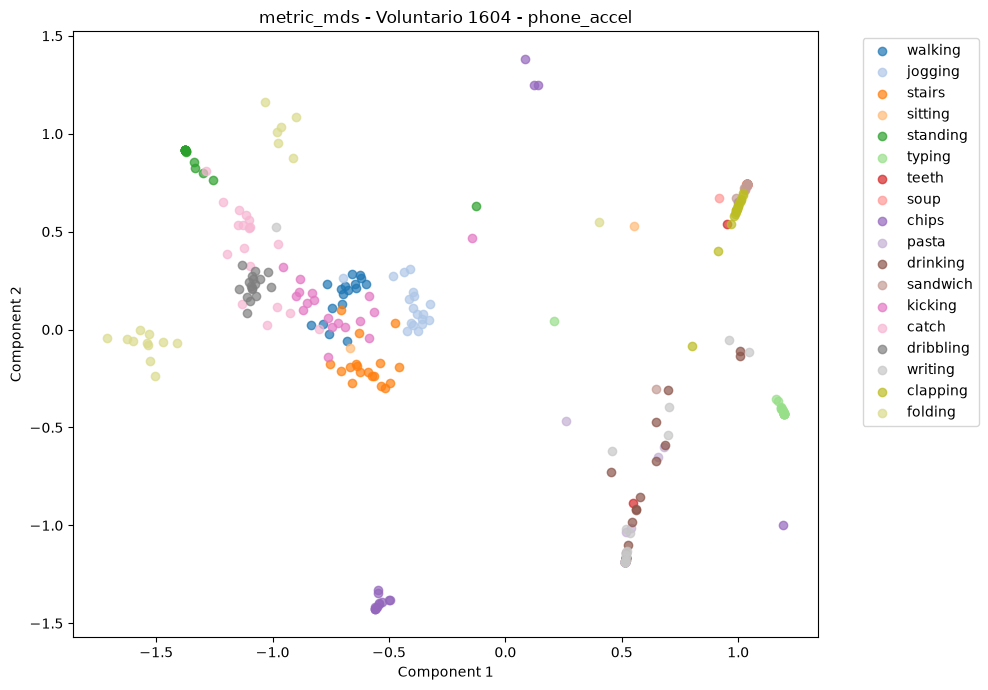

  Ejecutando nonmetric_mds...


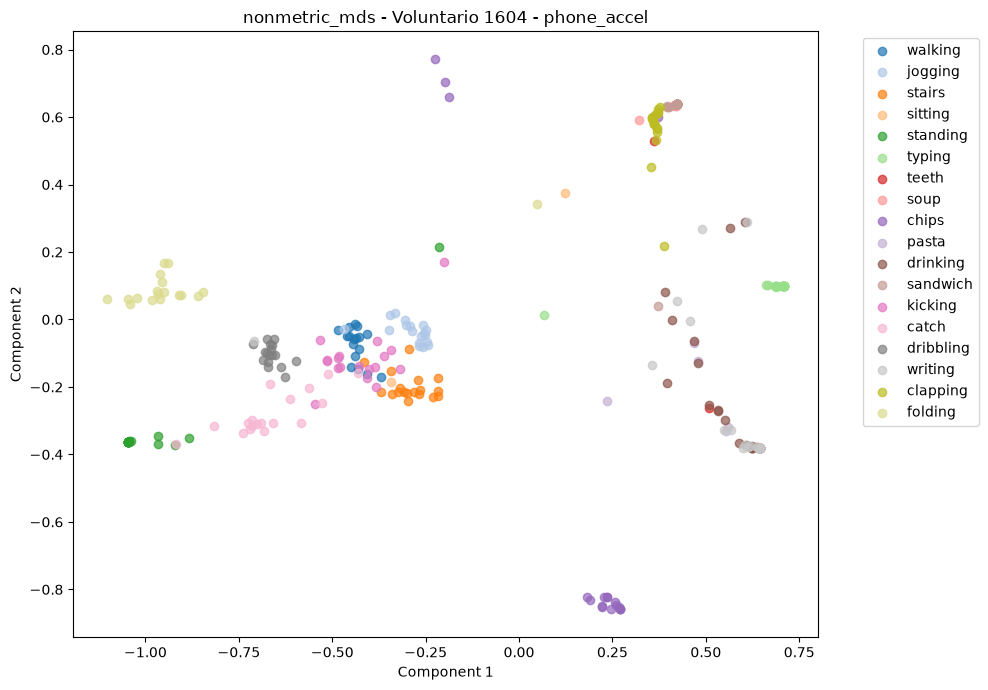

  Ejecutando umap...


/Users/franche/coding/Talleres_IA/Taller_06-Reducción/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


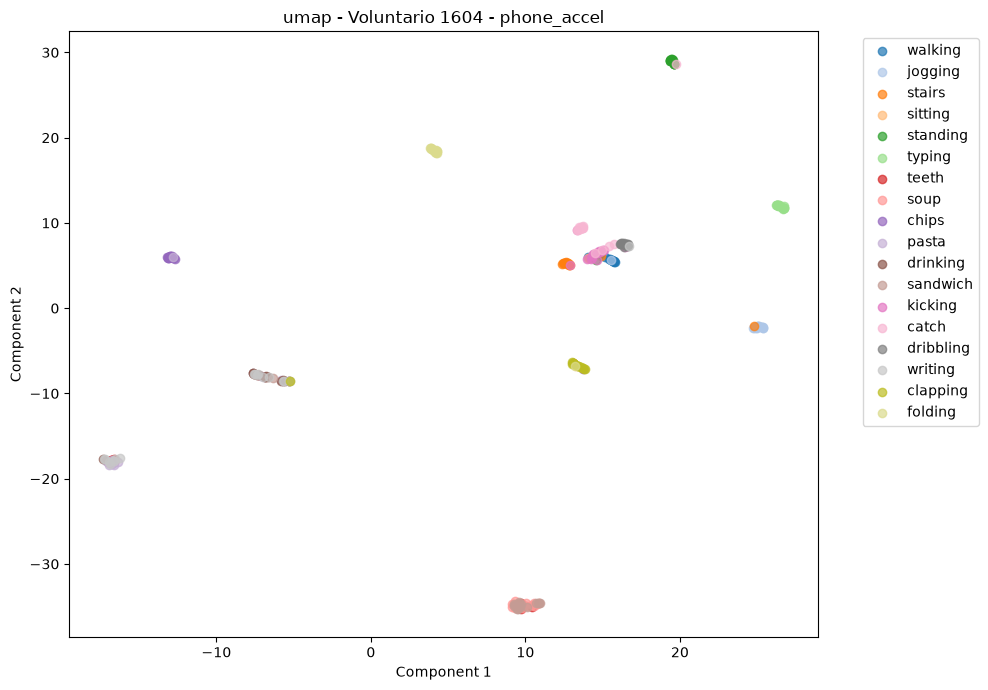


Voluntario: 1604
Caso: phone_gyro
Datos: (321, 30)
  Ejecutando pca...


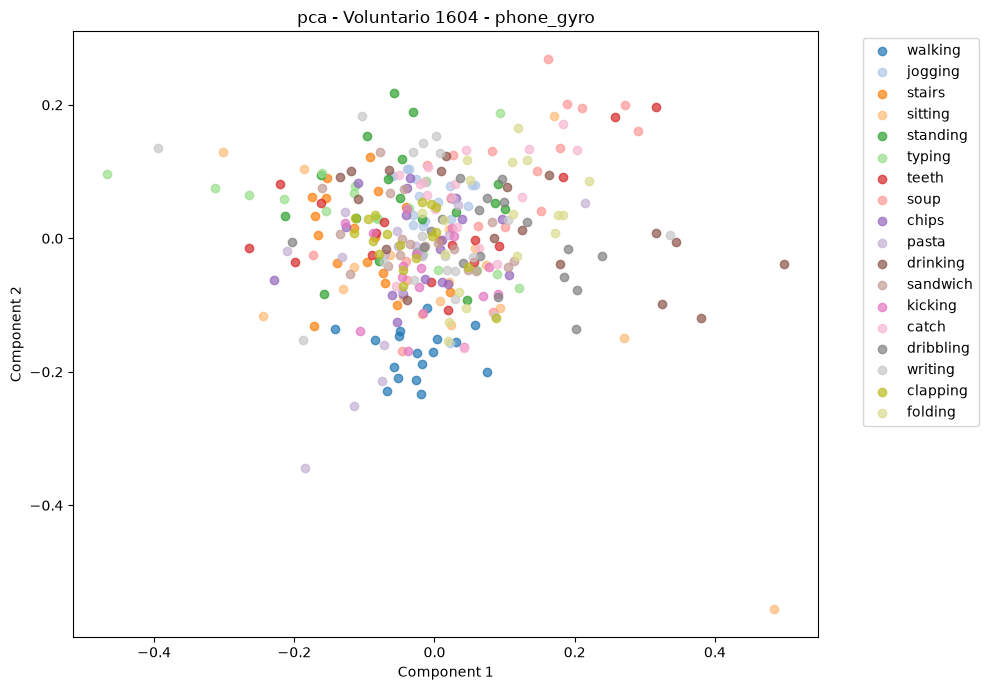

  Ejecutando classical_mds...


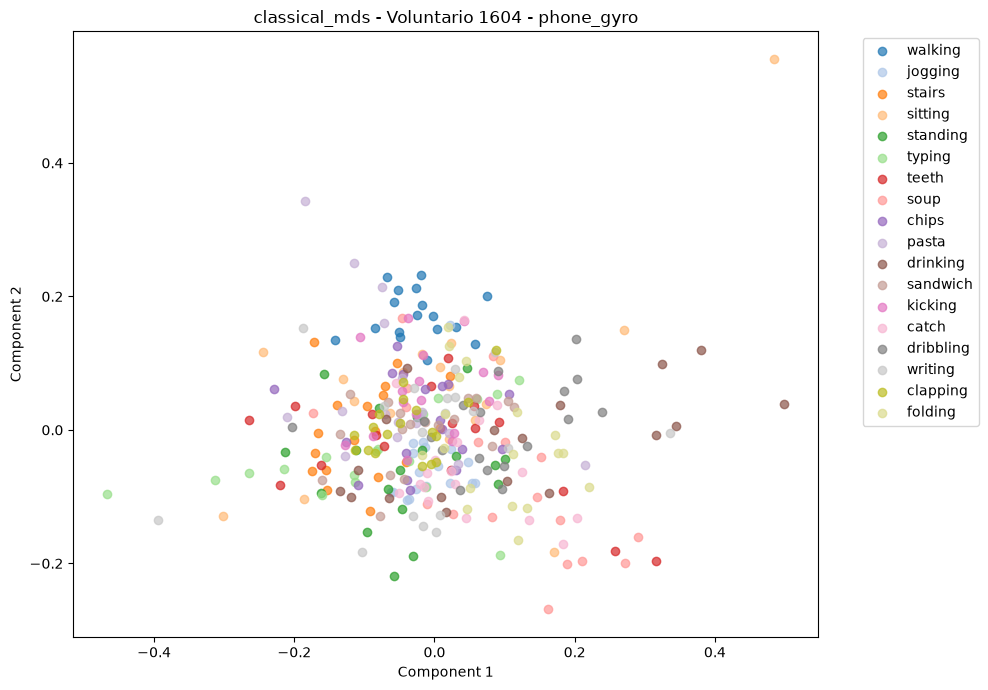

  Ejecutando metric_mds...


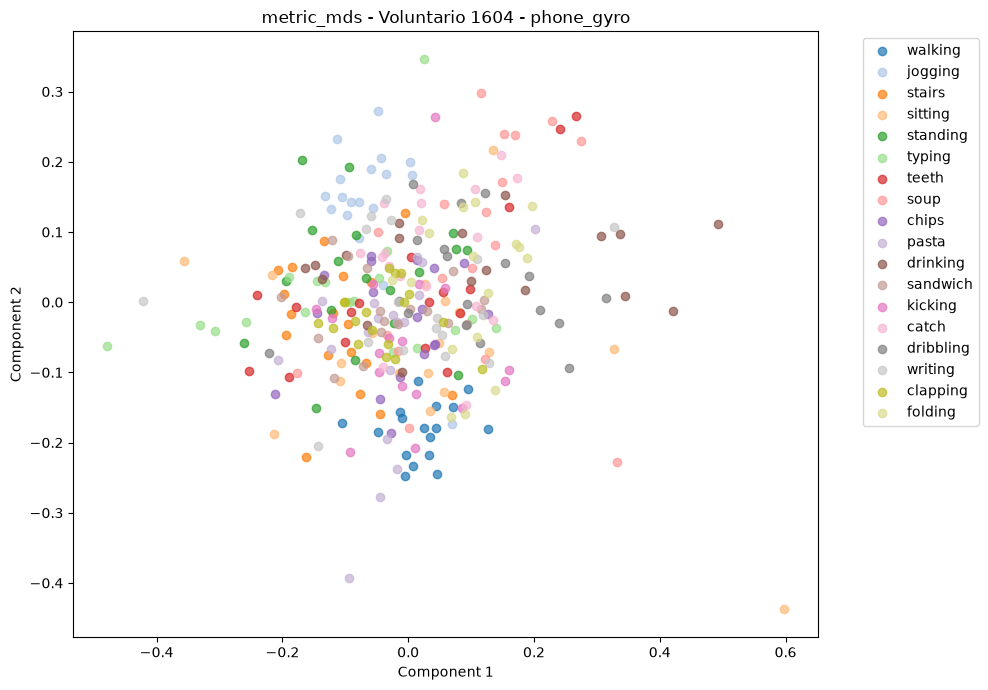

  Ejecutando nonmetric_mds...


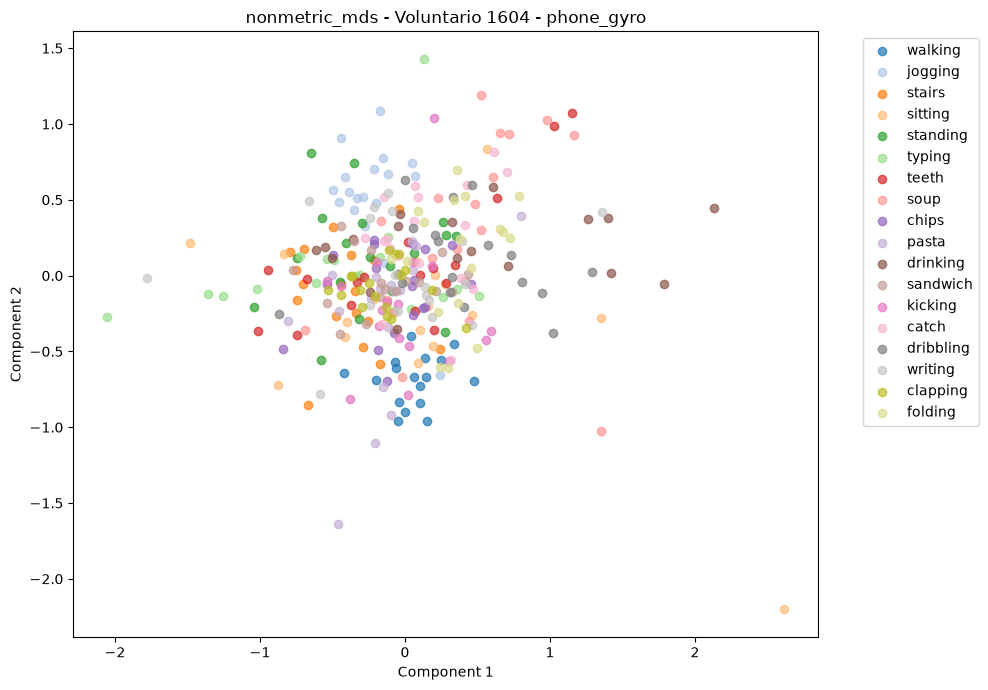

  Ejecutando umap...


/Users/franche/coding/Talleres_IA/Taller_06-Reducción/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


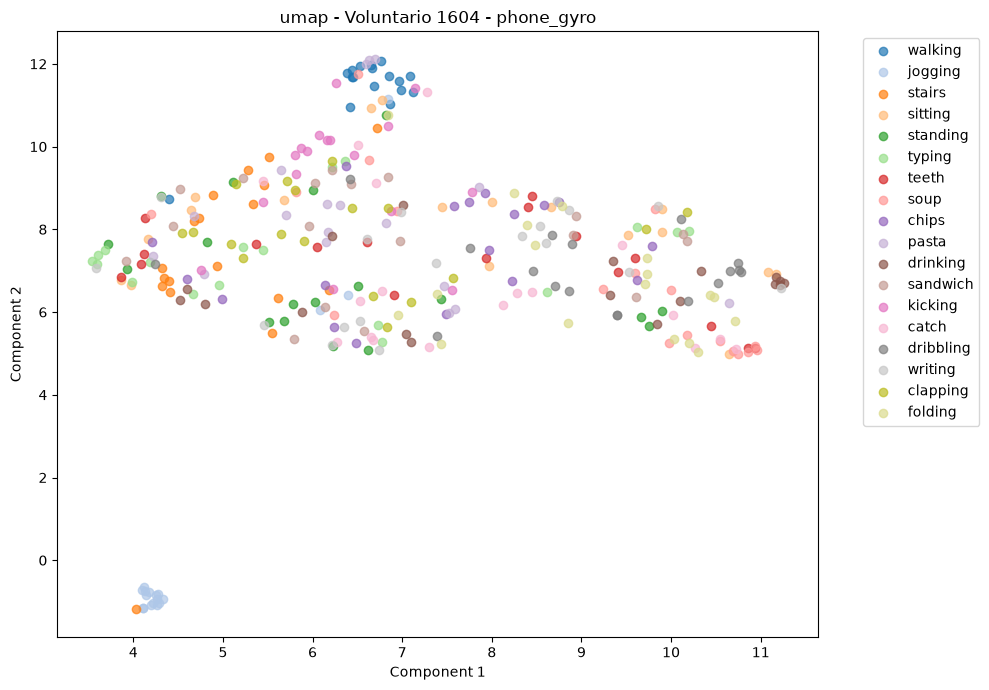


Voluntario: 1604
Caso: watch_accel
Datos: (324, 30)
  Ejecutando pca...


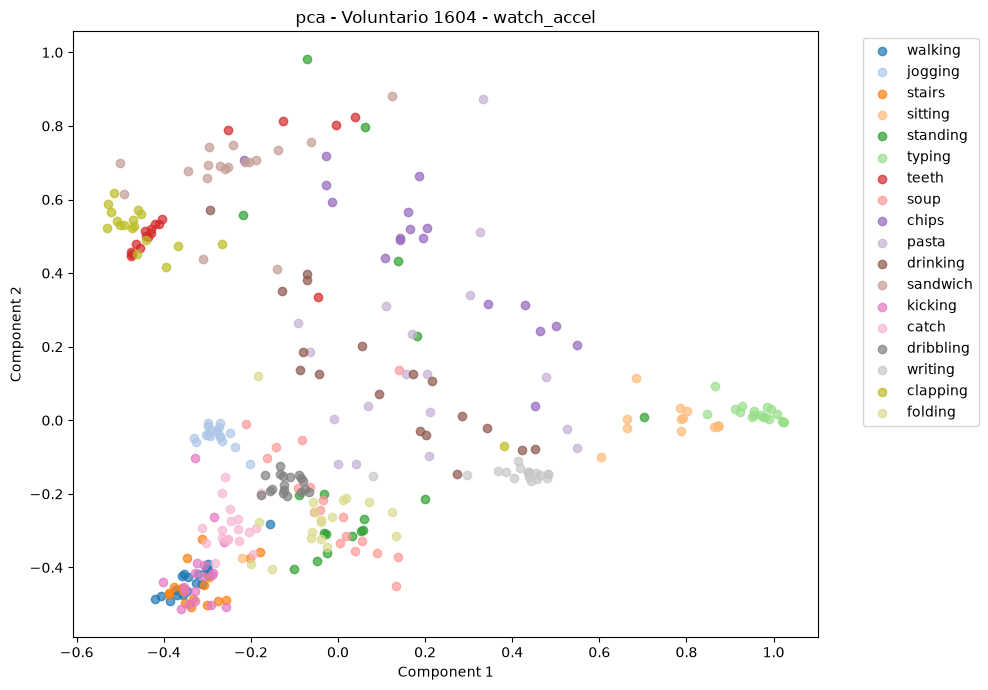

  Ejecutando classical_mds...


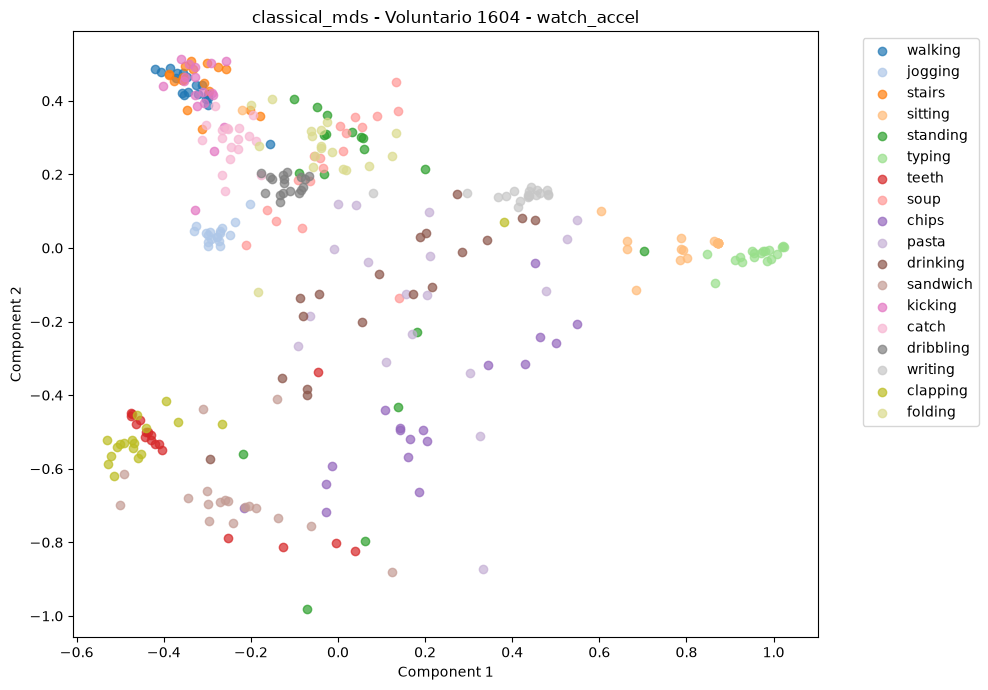

  Ejecutando metric_mds...


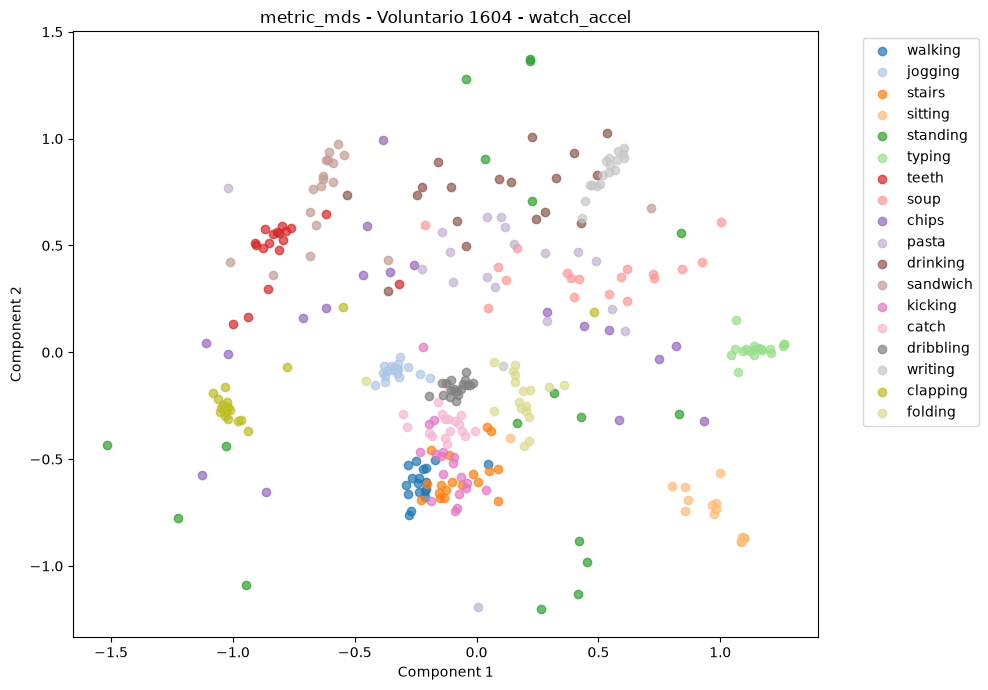

  Ejecutando nonmetric_mds...


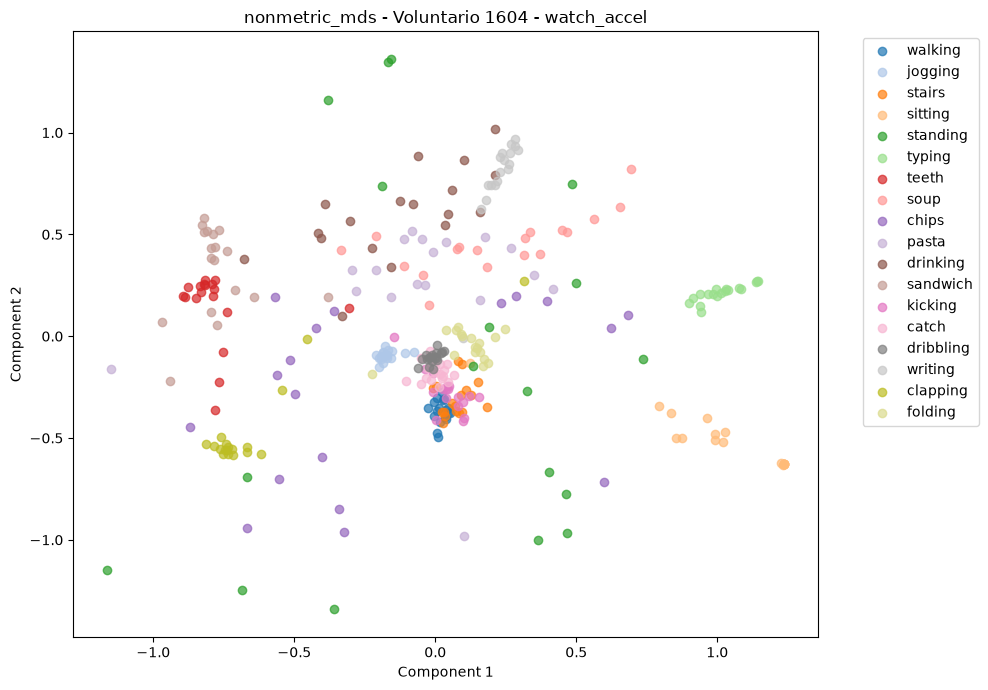

  Ejecutando umap...


/Users/franche/coding/Talleres_IA/Taller_06-Reducción/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


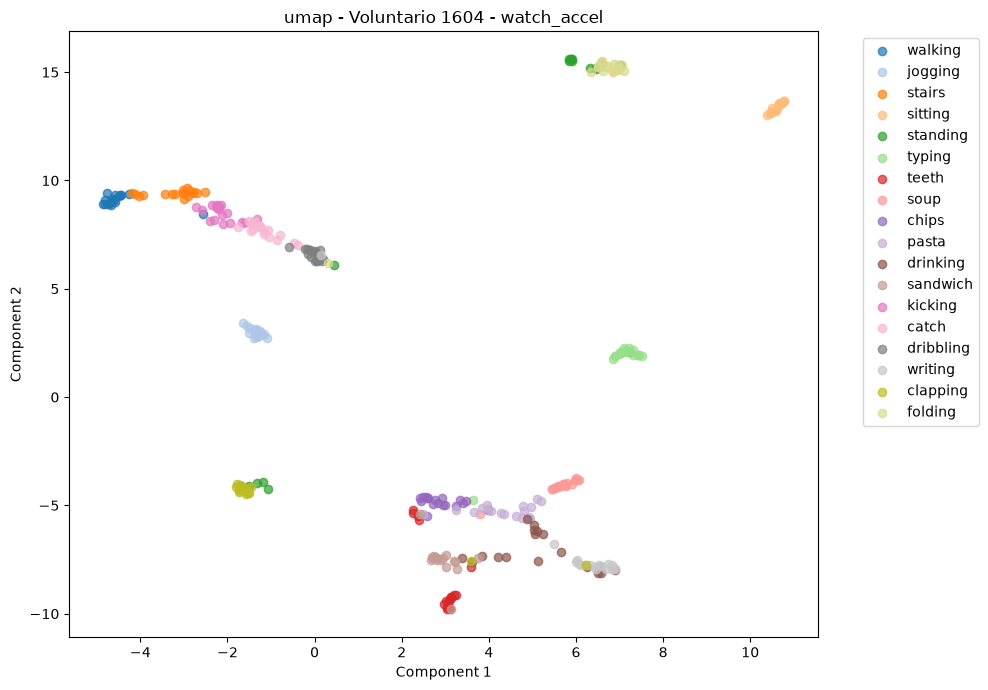


Voluntario: 1604
Caso: watch_gyro
Datos: (324, 30)
  Ejecutando pca...


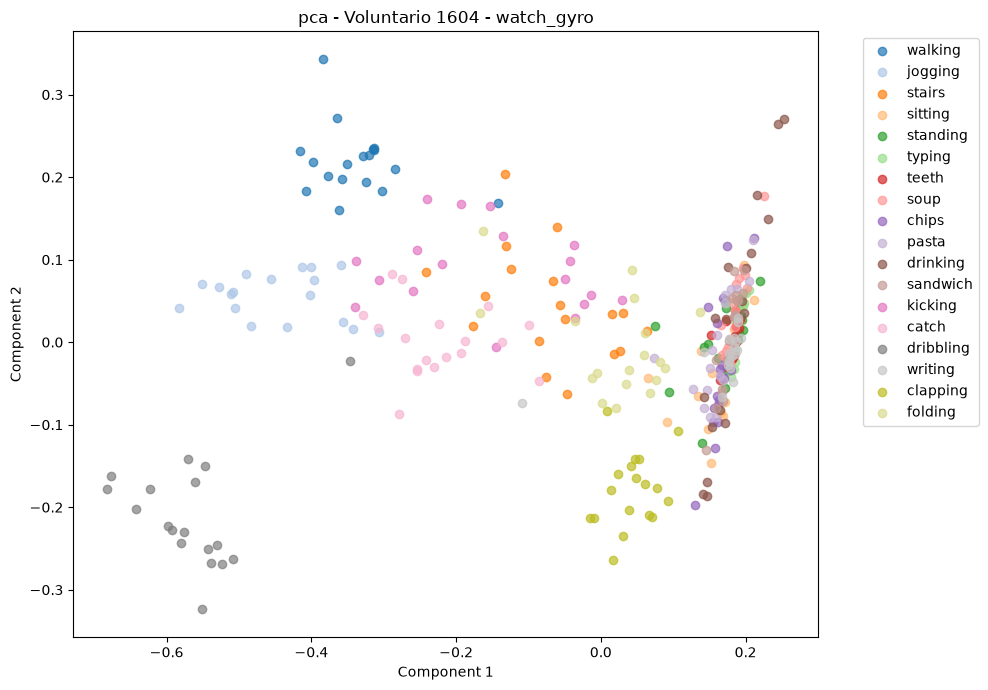

  Ejecutando classical_mds...


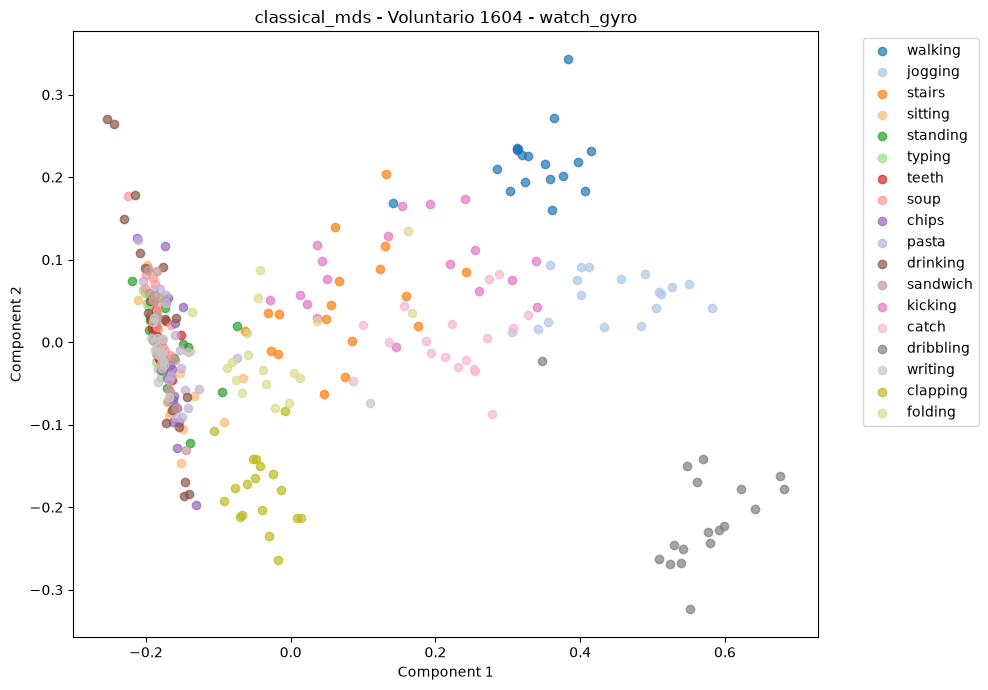

  Ejecutando metric_mds...


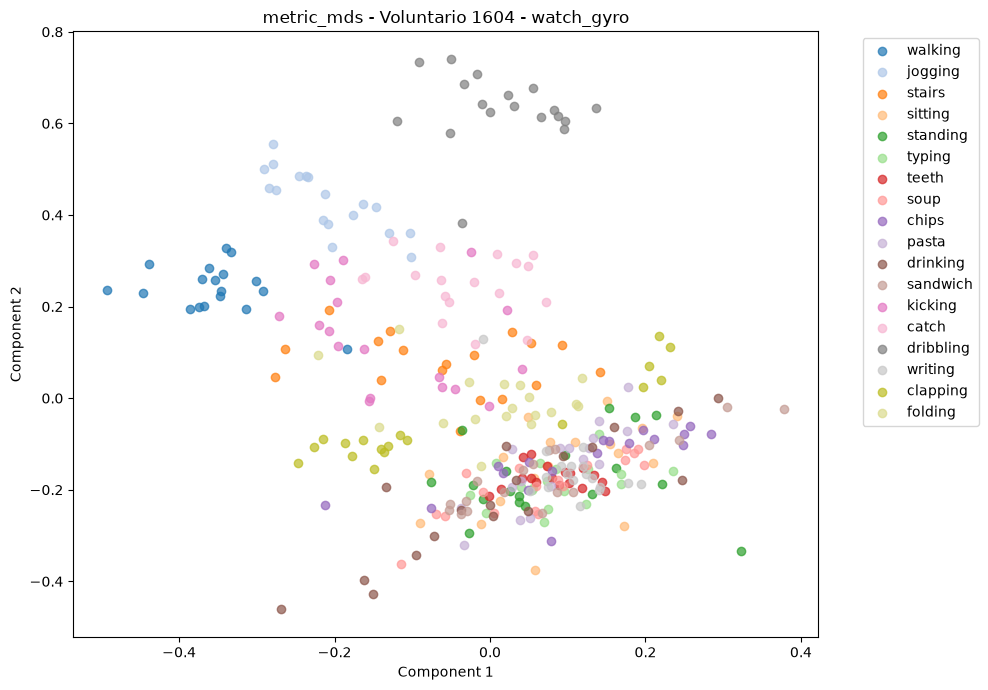

  Ejecutando nonmetric_mds...


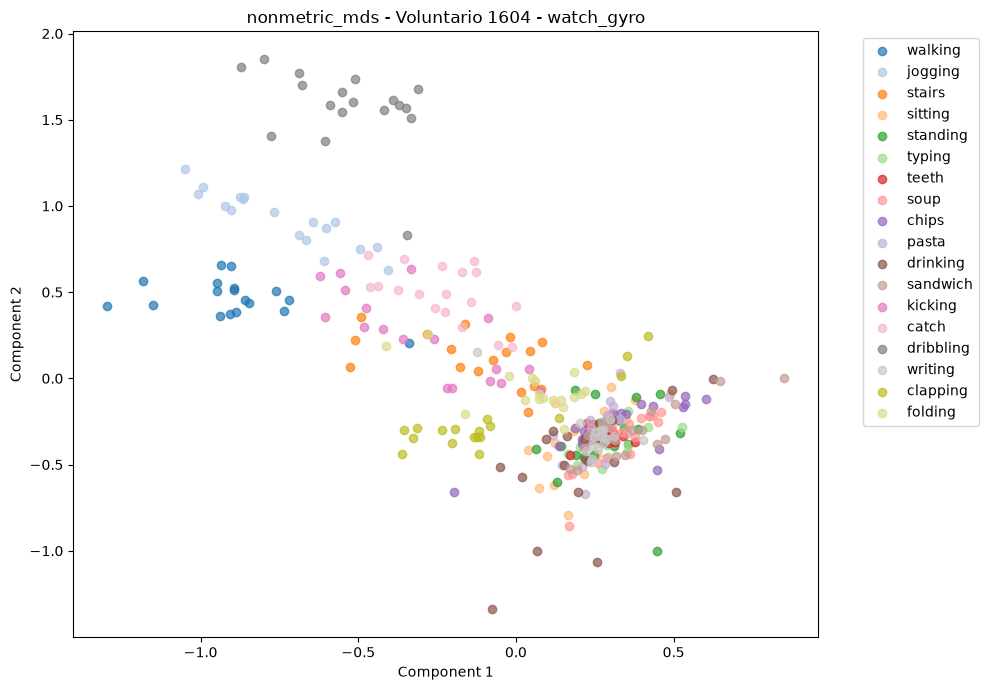

  Ejecutando umap...


/Users/franche/coding/Talleres_IA/Taller_06-Reducción/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


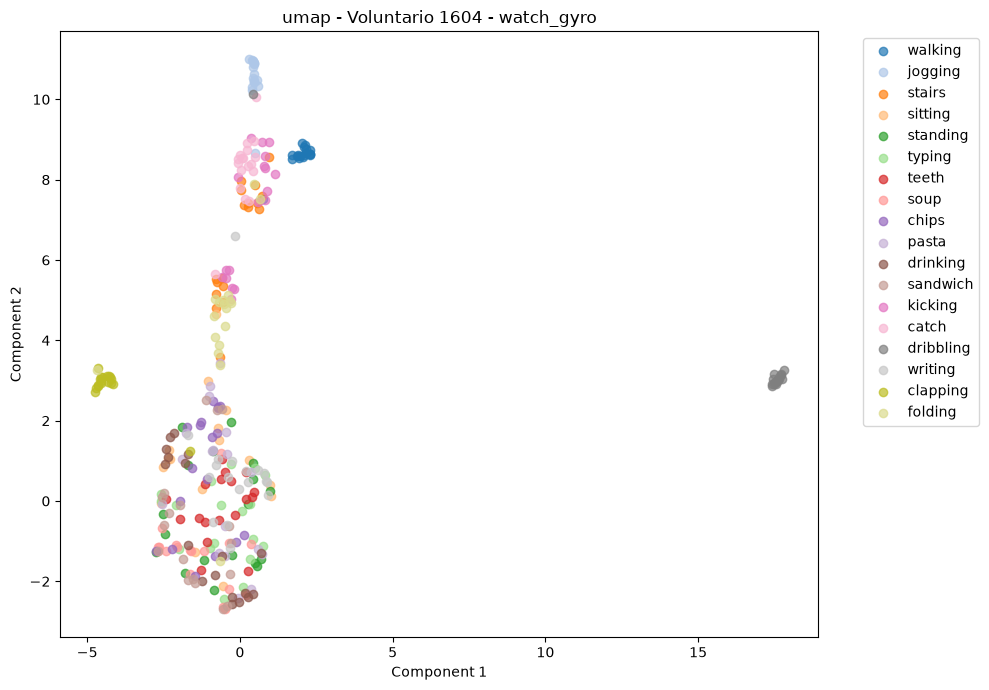


Voluntario: 1638
Caso: phone_accel
Datos: (324, 30)
  Ejecutando pca...


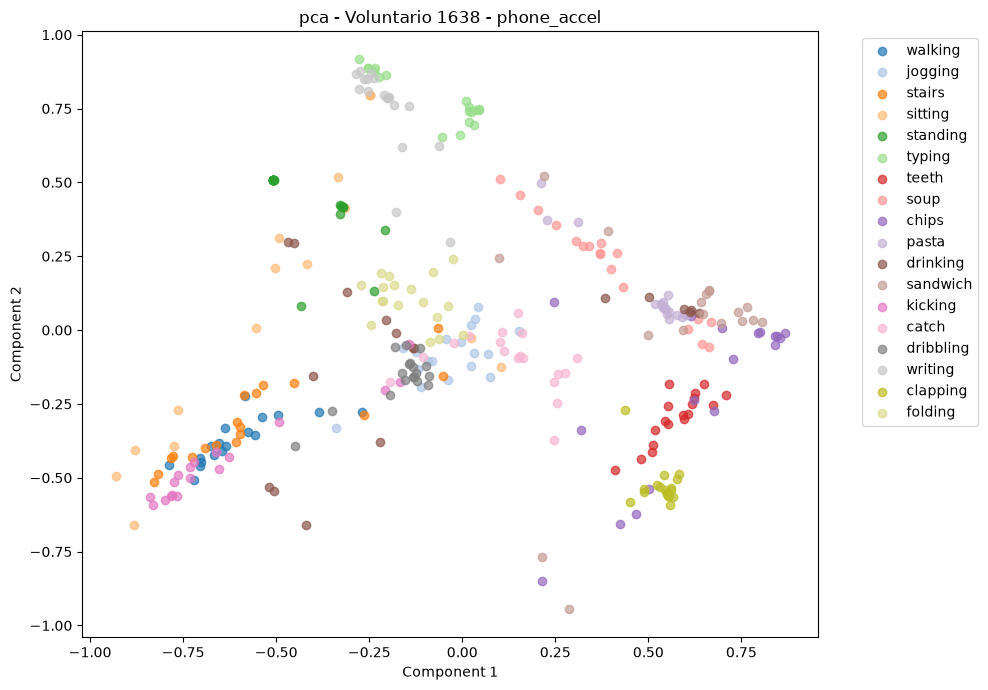

  Ejecutando classical_mds...


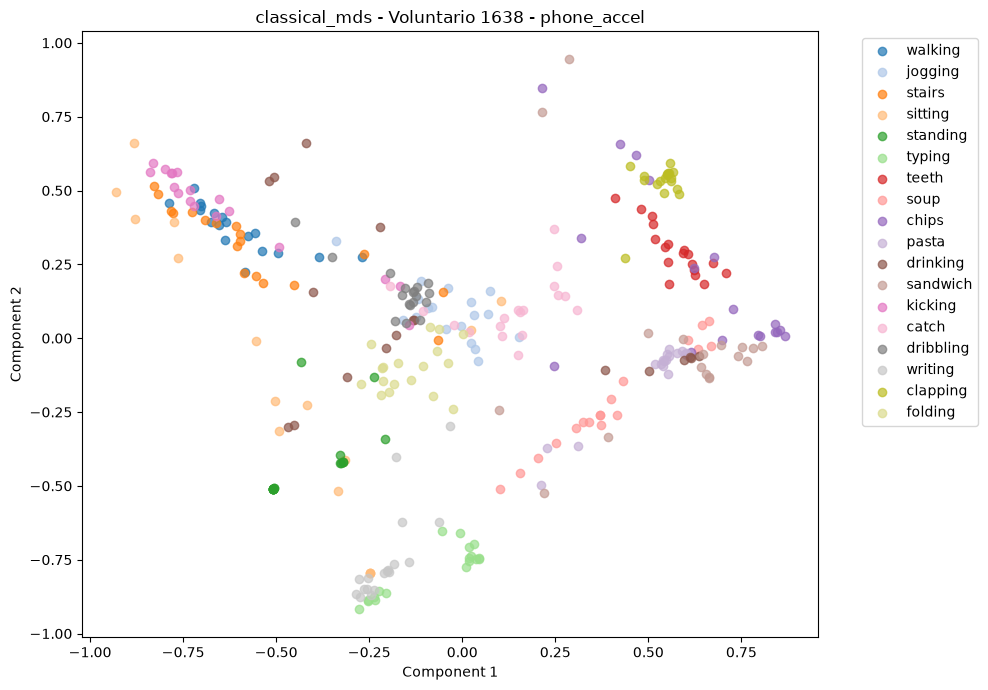

  Ejecutando metric_mds...


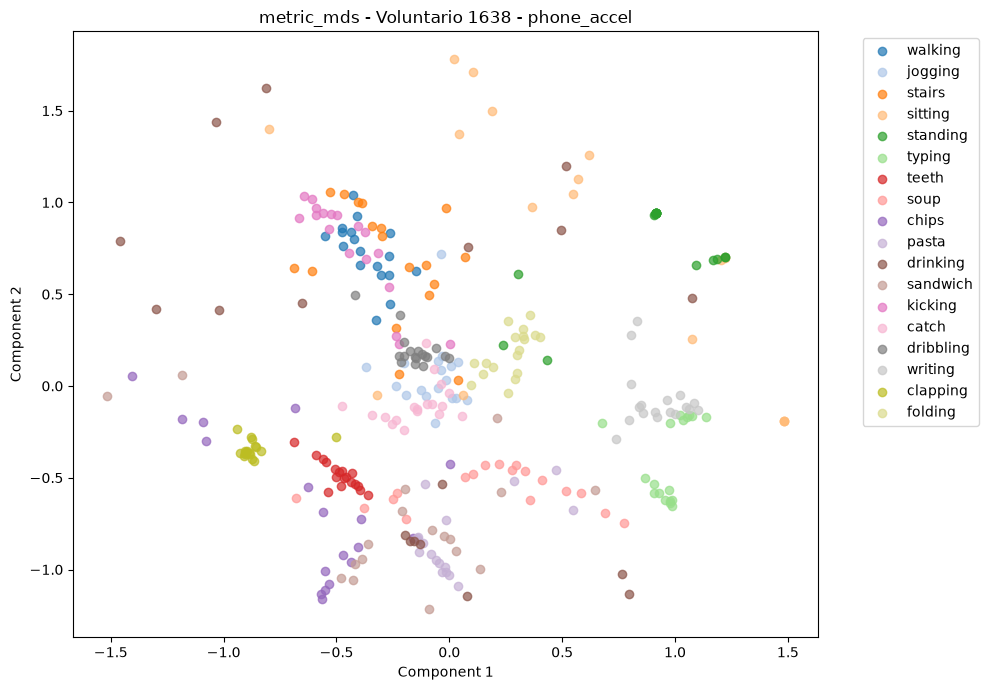

  Ejecutando nonmetric_mds...


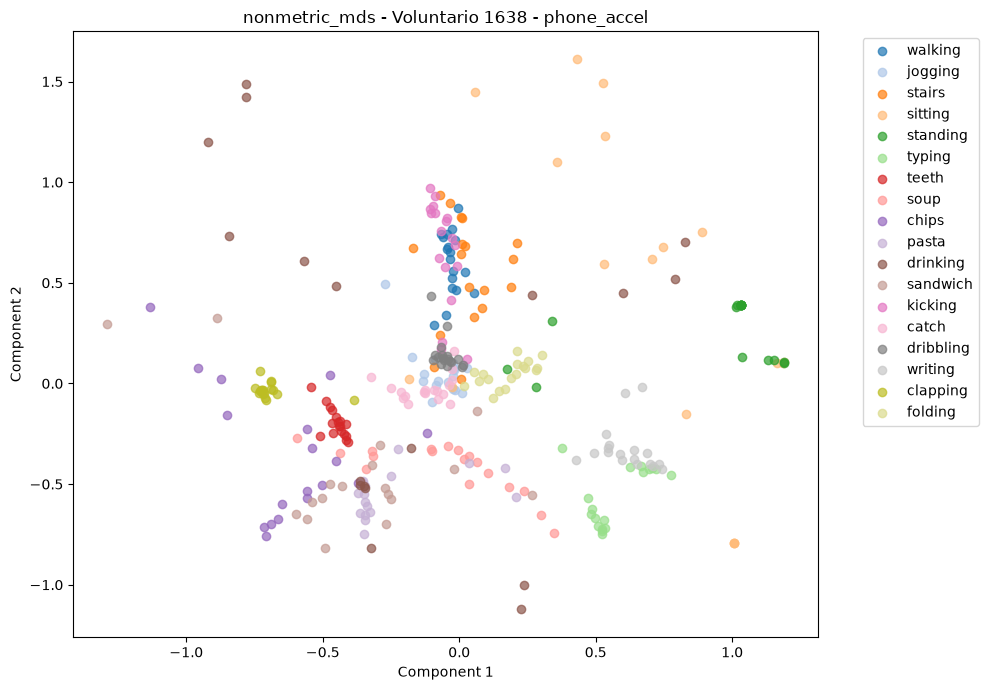

  Ejecutando umap...


/Users/franche/coding/Talleres_IA/Taller_06-Reducción/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


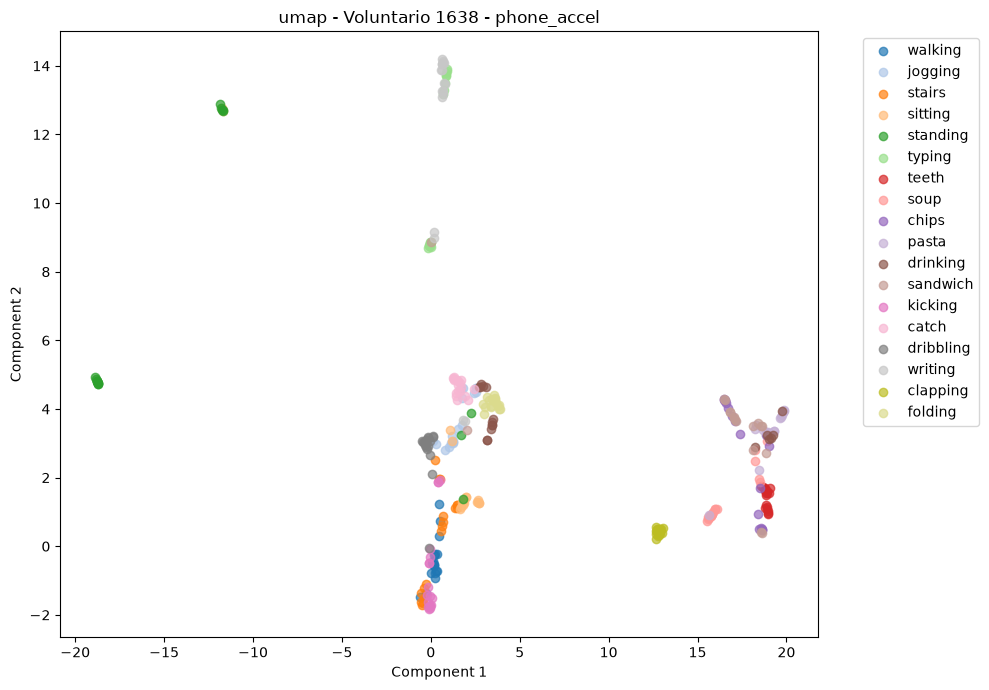


Voluntario: 1638
Caso: phone_gyro
Datos: (323, 30)
  Ejecutando pca...


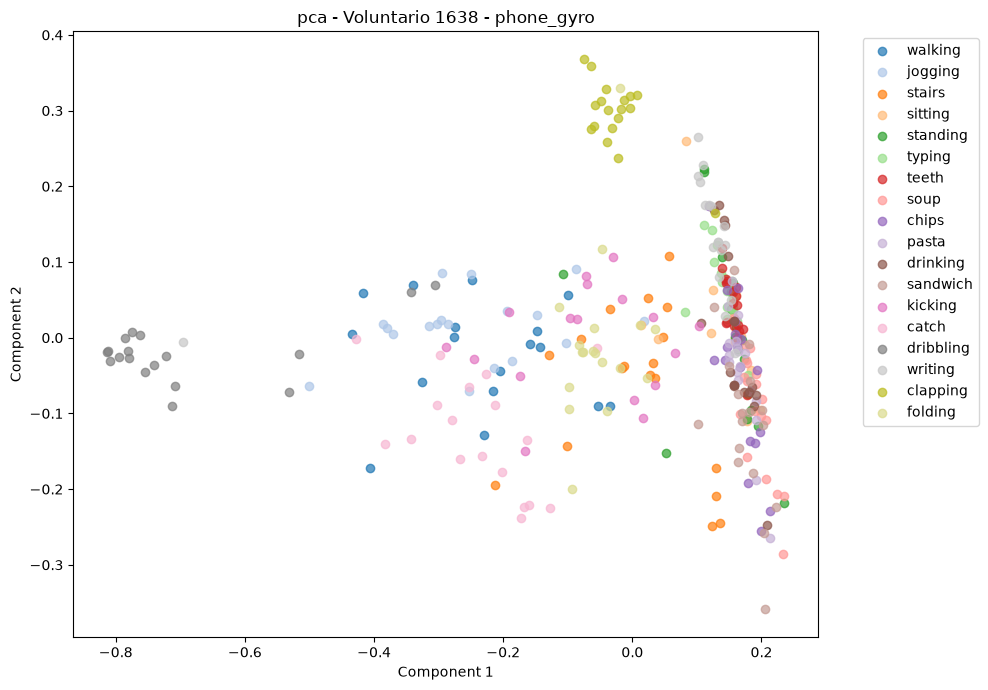

  Ejecutando classical_mds...


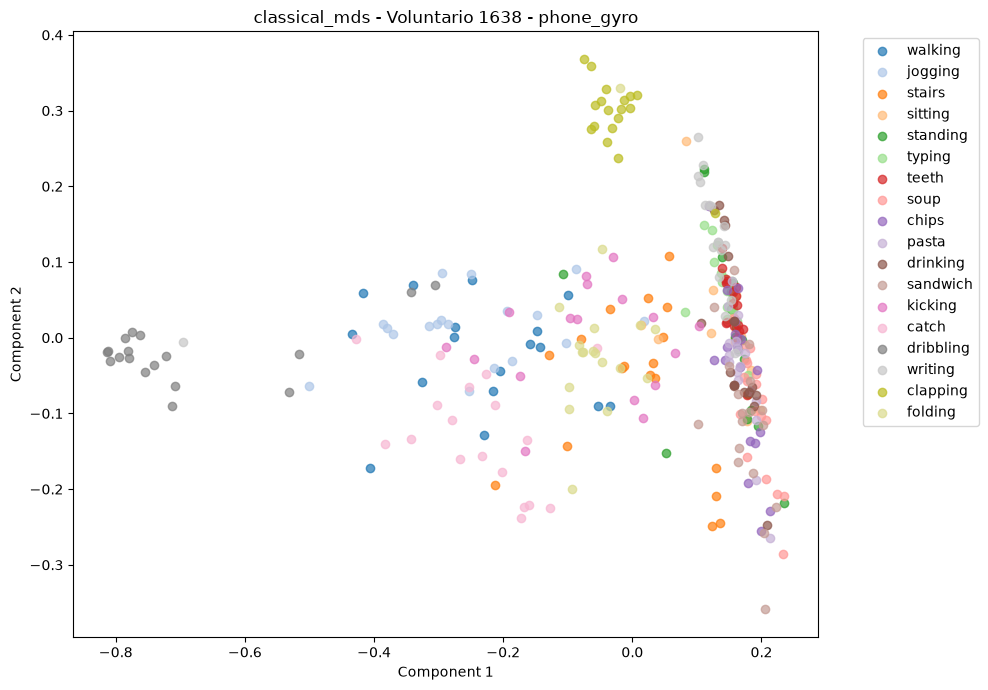

  Ejecutando metric_mds...


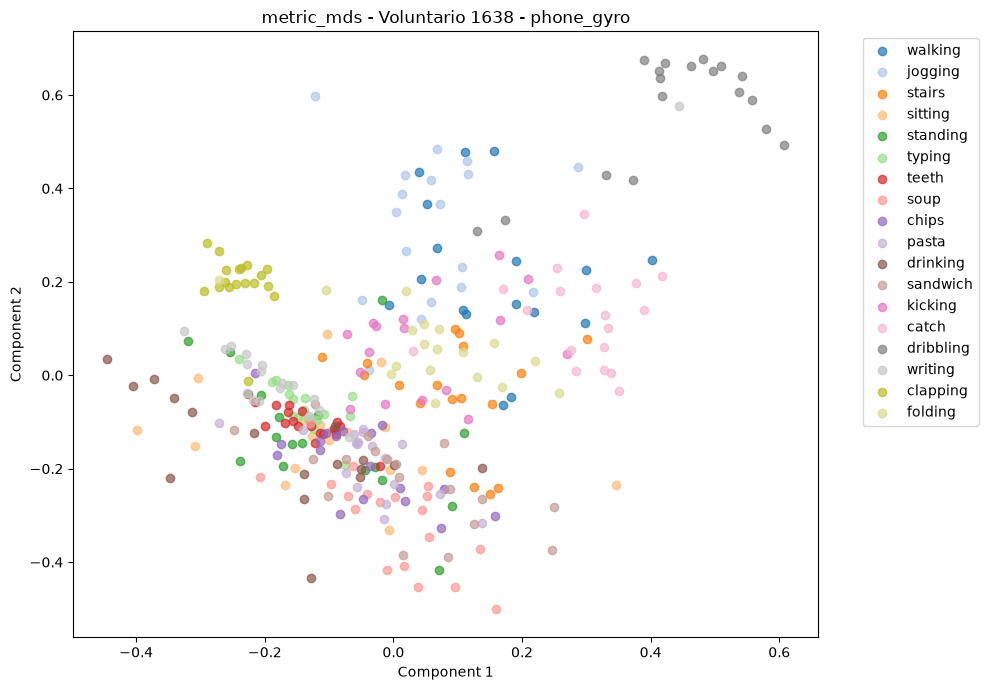

  Ejecutando nonmetric_mds...


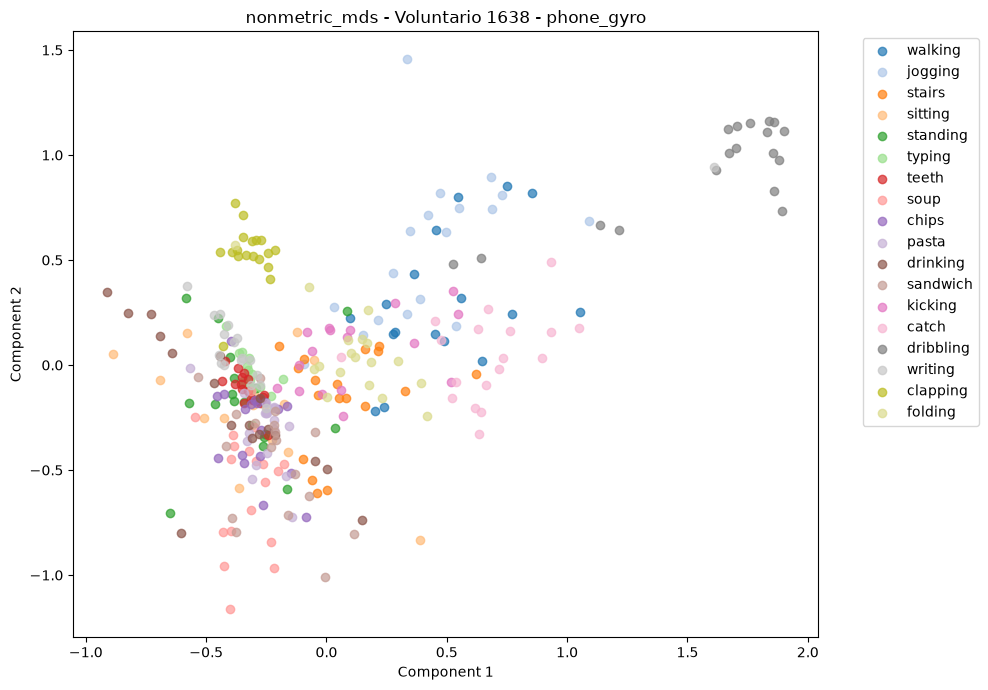

  Ejecutando umap...


/Users/franche/coding/Talleres_IA/Taller_06-Reducción/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


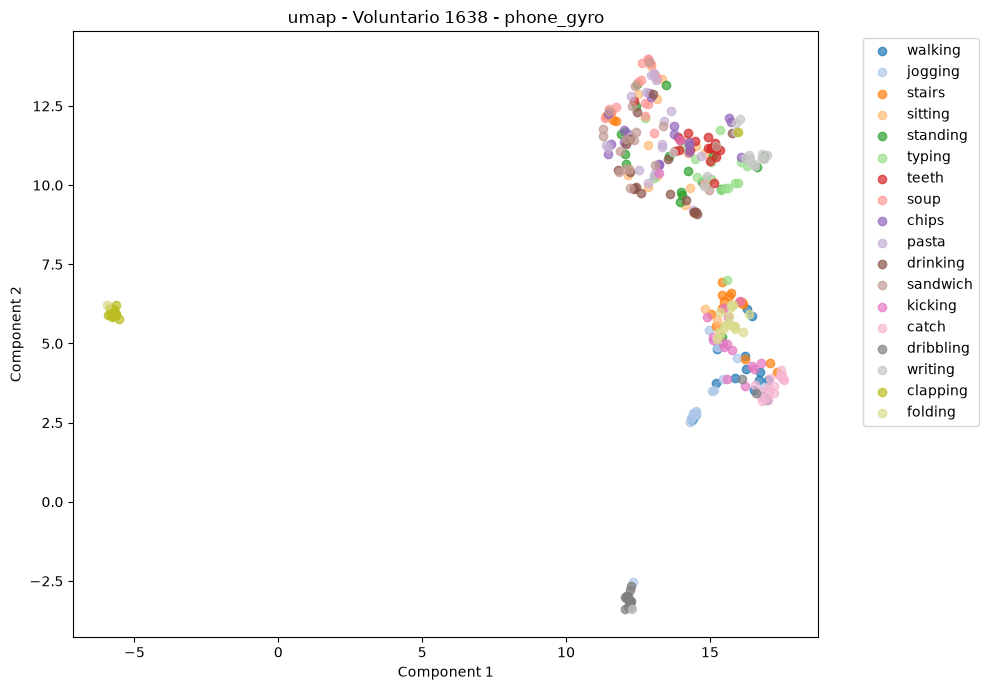


Voluntario: 1638
Caso: watch_accel
Datos: (803, 30)
  Ejecutando pca...


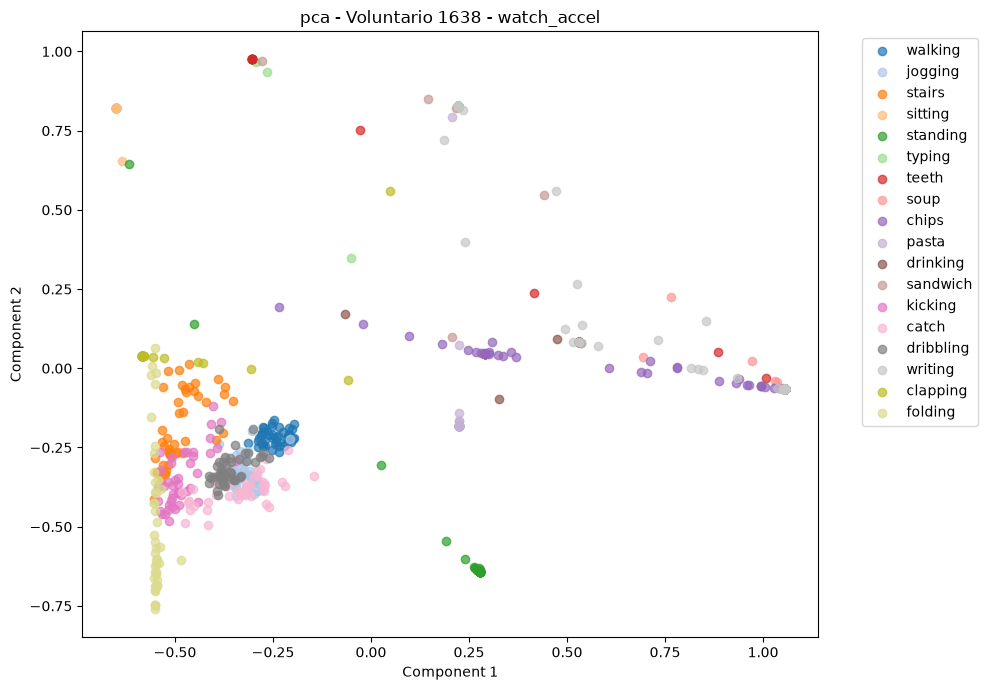

  Ejecutando classical_mds...


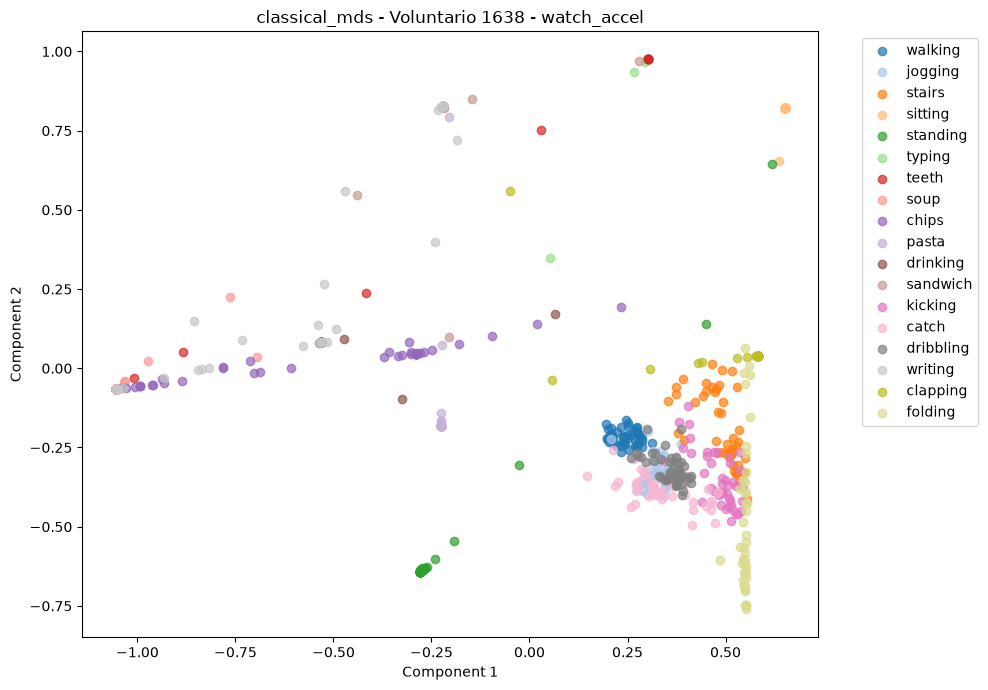

  Ejecutando metric_mds...


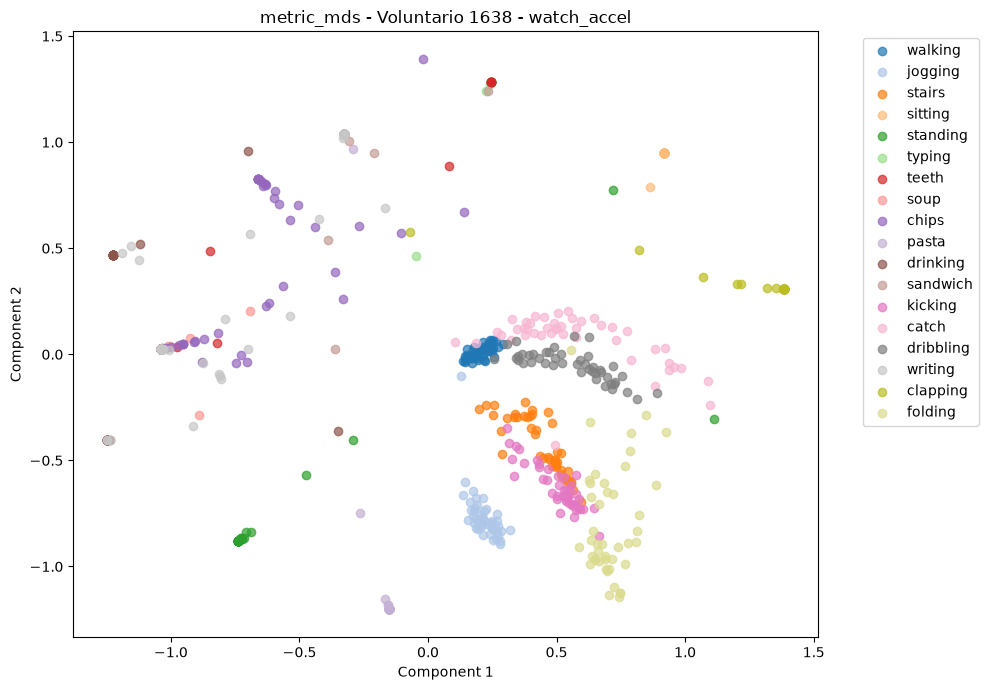

  Ejecutando nonmetric_mds...


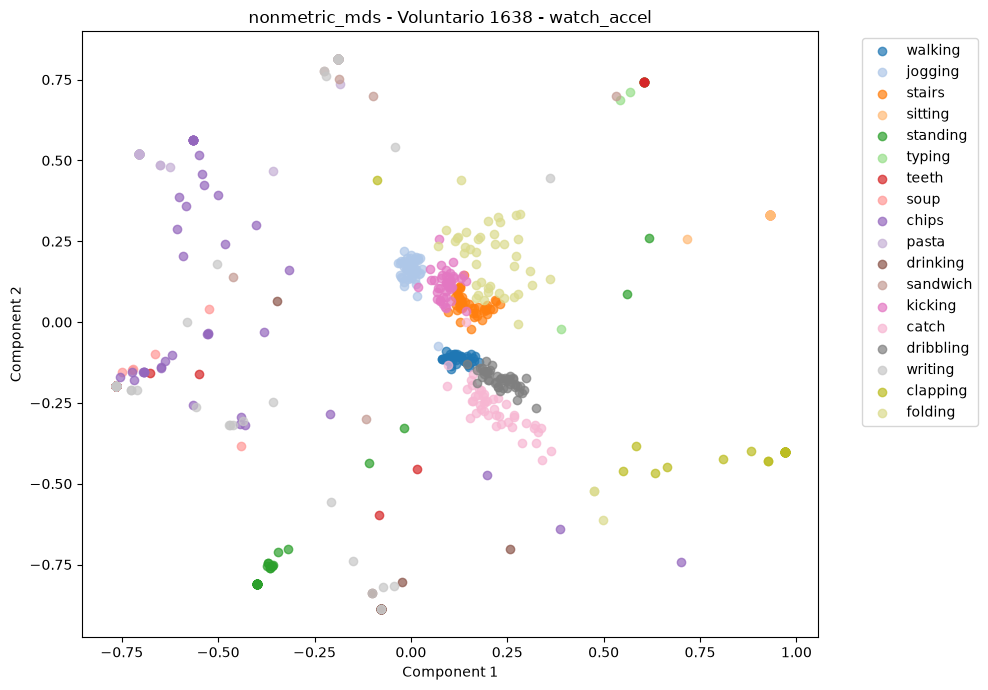

  Ejecutando umap...


/Users/franche/coding/Talleres_IA/Taller_06-Reducción/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


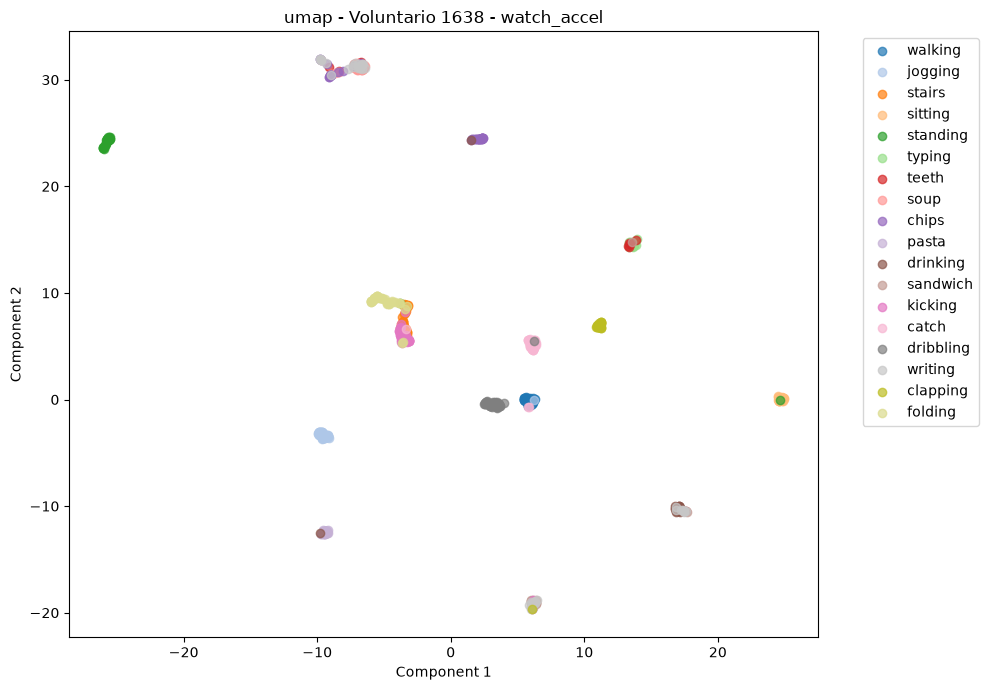


Voluntario: 1638
Caso: watch_gyro
Datos: (357, 30)
  Ejecutando pca...


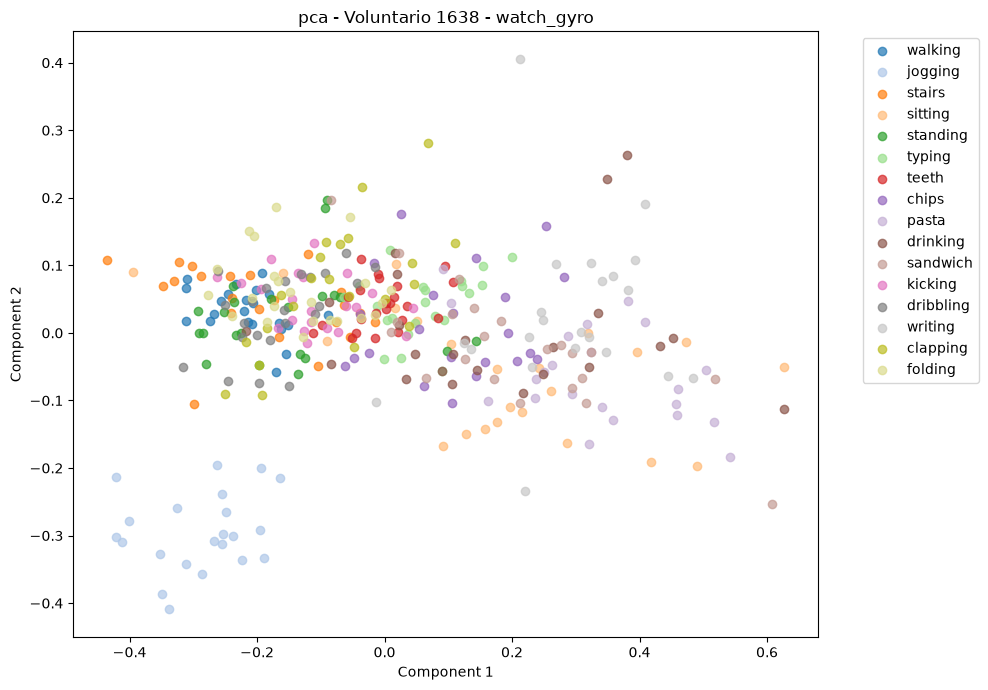

  Ejecutando classical_mds...


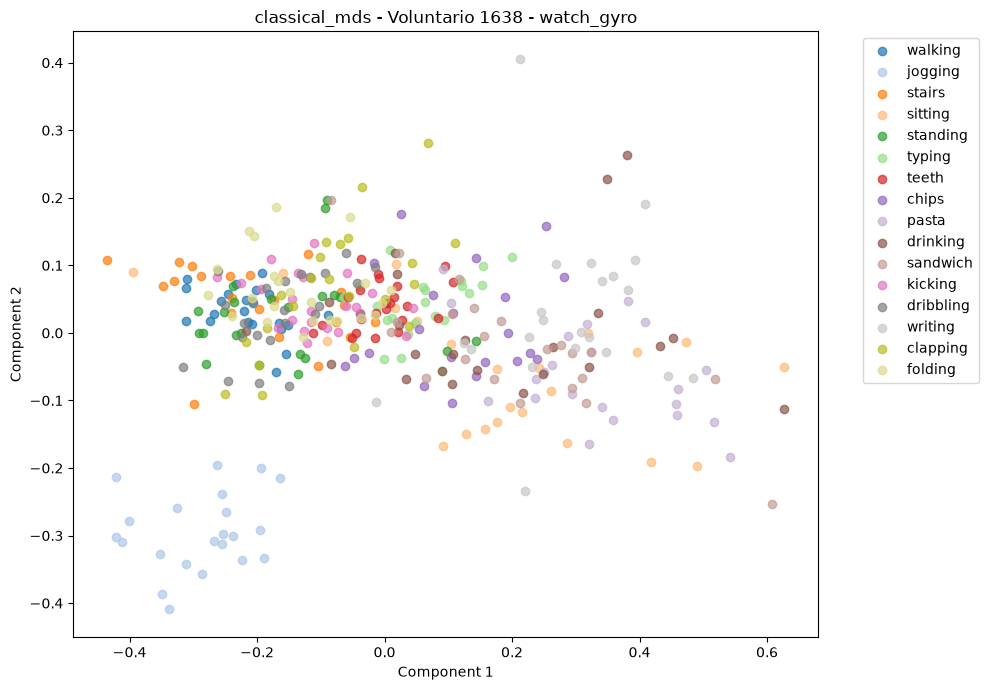

  Ejecutando metric_mds...


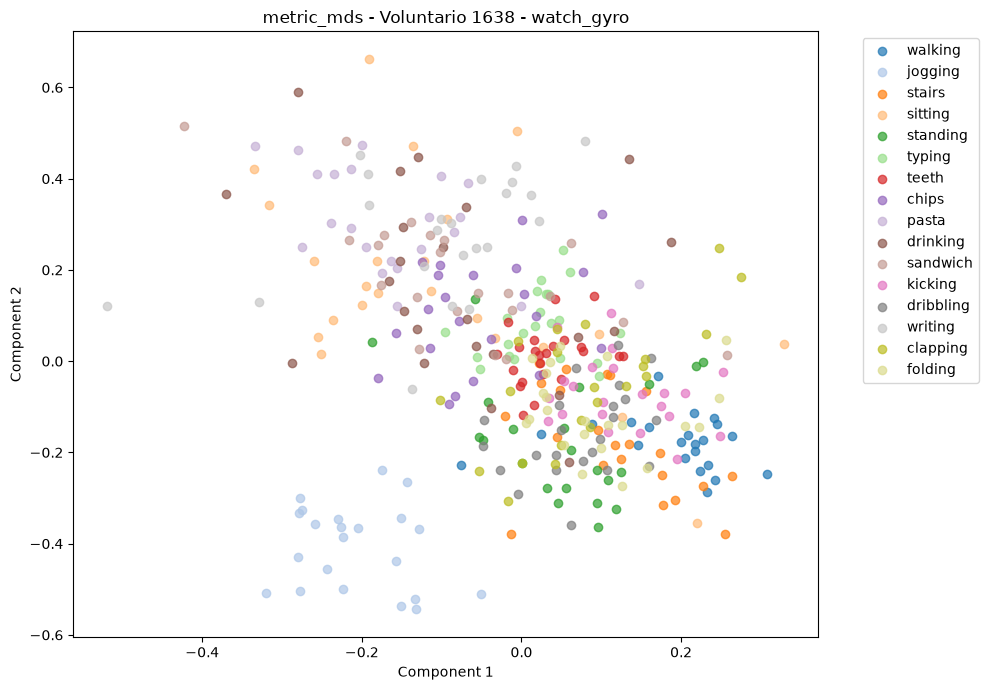

  Ejecutando nonmetric_mds...


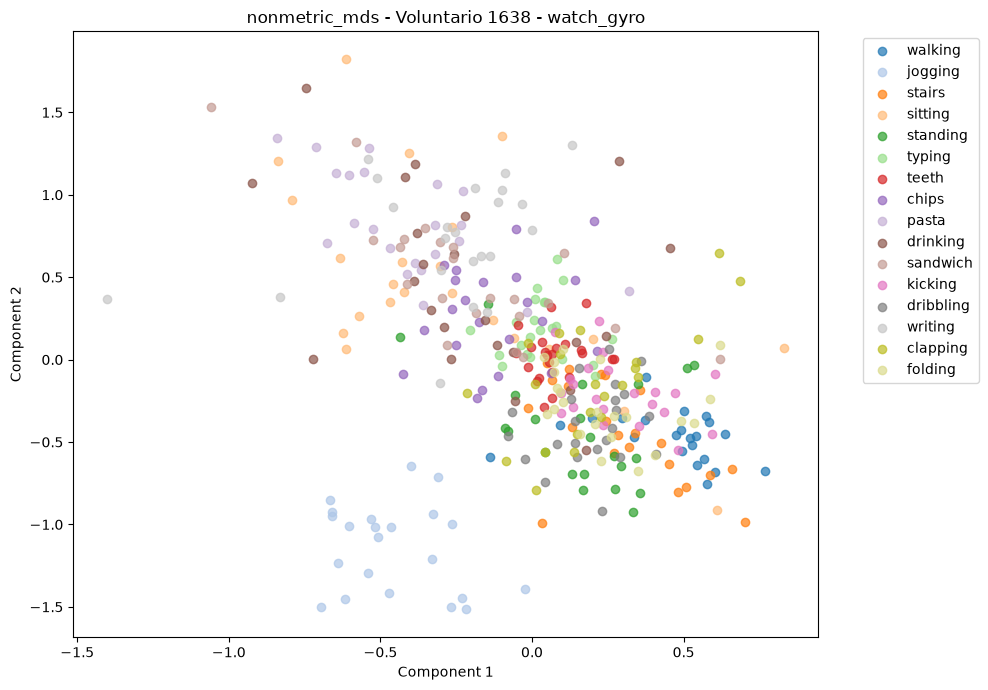

  Ejecutando umap...


/Users/franche/coding/Talleres_IA/Taller_06-Reducción/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


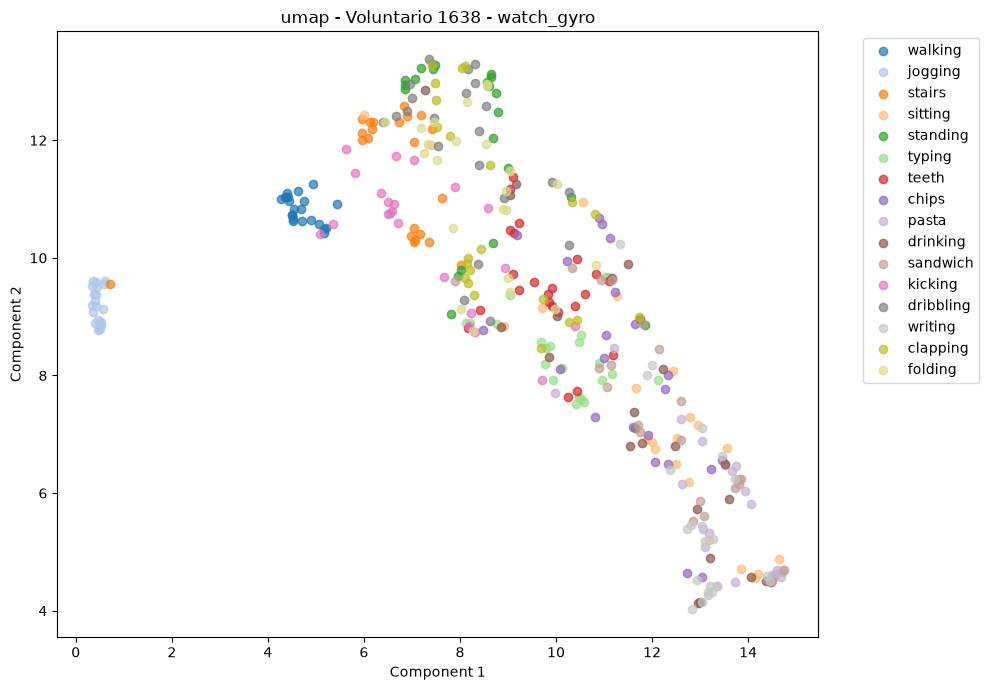

In [51]:
all_individual_results = {}

for subject_id in selected_subjects:
    
    all_individual_results[subject_id] = {}
    
    for case_name in cases:
        
        all_individual_results[subject_id][case_name] = analyze_subject(
            subject_id,
            case_name
        )

In [52]:
summary_individual = []

for subject_id in selected_subjects:
    
    for case_name in cases:
        
        for method in methods:
            
            info = all_individual_results[
                subject_id
            ][
                case_name
            ][
                method
            ]["info"]
            
            row = {
                "subject": subject_id,
                "case": case_name,
                "method": method
            }
            
            if "explained_variance" in info:
                row["explained_variance"] = info["explained_variance"]
            
            if "stress" in info:
                row["stress"] = info["stress"]
            
            summary_individual.append(row)

summary_individual = pd.DataFrame(summary_individual)

summary_individual

,subject,case,method,explained_variance,stress
0,1633,phone_accel,pca,0.801769,NaN
1,1633,phone_accel,classical_mds,NaN,NaN
2,1633,phone_accel,metric_mds,NaN,1774.007881
3,1633,phone_accel,nonmetric_mds,NaN,0.108286
4,1633,phone_accel,umap,NaN,NaN
5,1633,phone_gyro,pca,0.625279,NaN
6,1633,phone_gyro,classical_mds,NaN,NaN
7,1633,phone_gyro,metric_mds,NaN,139.718056
8,1633,phone_gyro,nonmetric_mds,NaN,0.170054
9,1633,phone_gyro,umap,NaN,NaN


## 5. Análisis combinado de los voluntarios

In [54]:
def combine_subjects(case_name):
    X_list = []
    y_list = []

    device, sensor = cases[case_name]

    for subject_id in selected_subjects:
        X, y = prepare_subject(subject_id, device, sensor)

        X_list.append(X)
        y_list.append(y)

    X_combined = pd.concat(X_list, ignore_index=True)
    y_combined = pd.concat(y_list, ignore_index=True)

    return X_combined, y_combined

In [56]:
def analyze_combined(case_name):
    X, y = combine_subjects(case_name)

    y_names = y.map(activity_map)

    results = {}

    print(f"\nCaso combinado: {case_name}")
    print(f"Datos: {X.shape}")

    for method in methods:
        print(f"  Ejecutando {method}...")

        X_reduced, info = reduce_dimensions(X, method)

        results[method] = {
            "X_reduced": X_reduced,
            "info": info
        }

        plot_embedding(
            X_reduced,
            y_names,
            title=f"{method} - 3 voluntarios - {case_name}"
        )

    return results


Caso combinado: phone_accel
Datos: (1074, 30)
  Ejecutando pca...


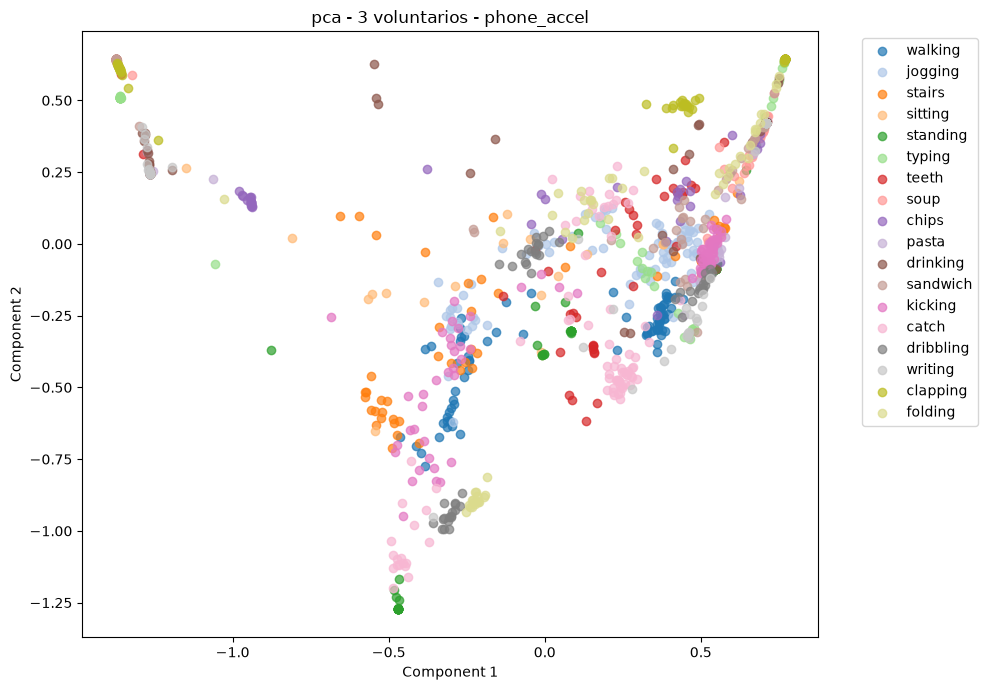

  Ejecutando classical_mds...


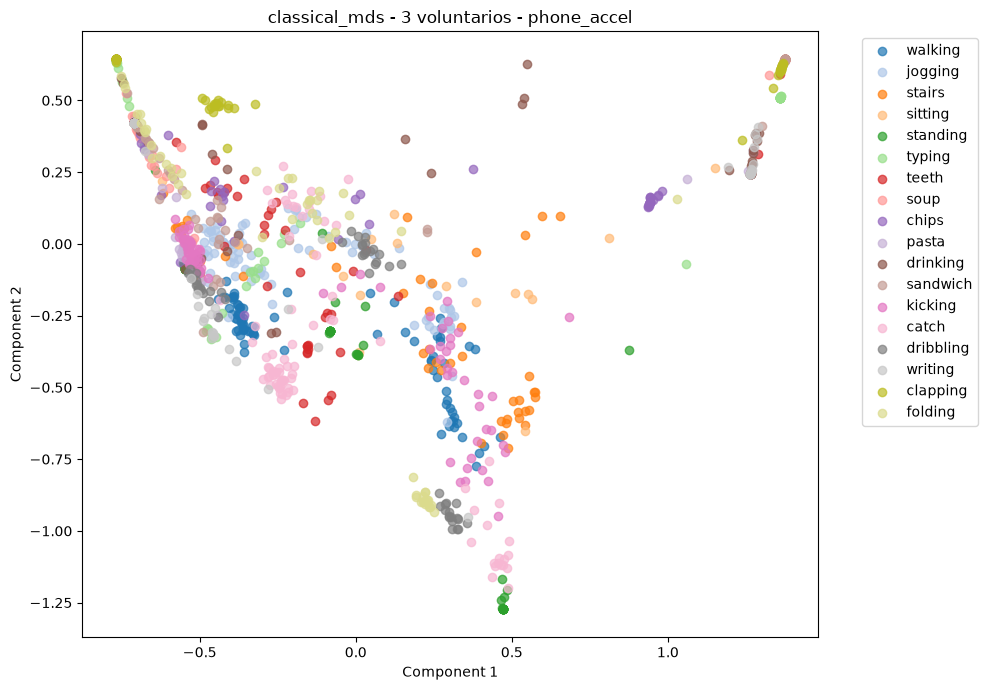

  Ejecutando metric_mds...


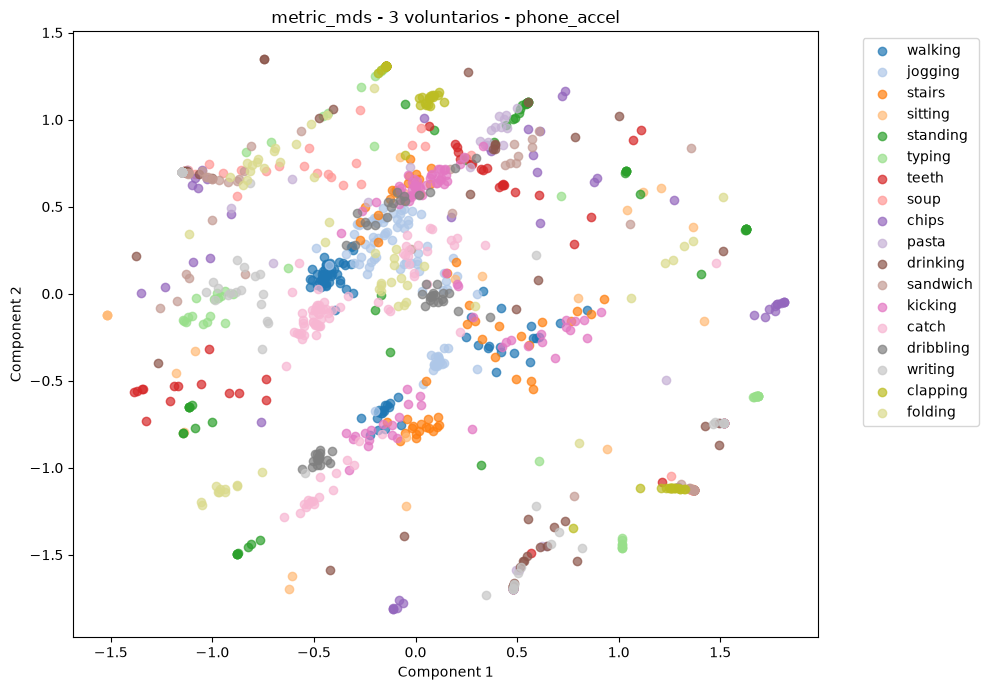

  Ejecutando nonmetric_mds...


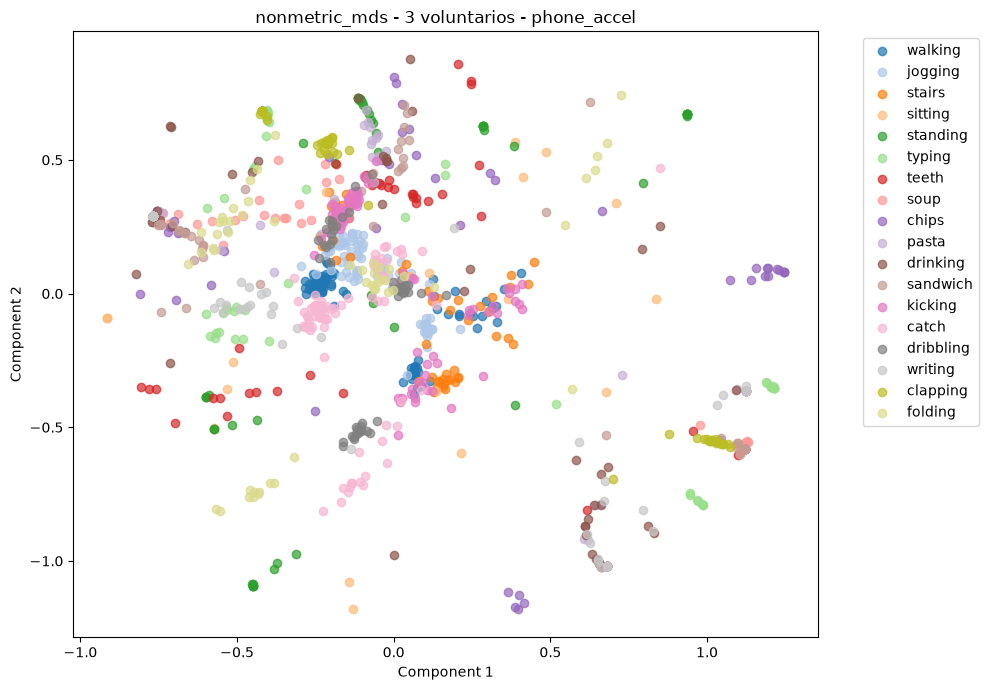

  Ejecutando umap...


/Users/franche/coding/Talleres_IA/Taller_06-Reducción/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


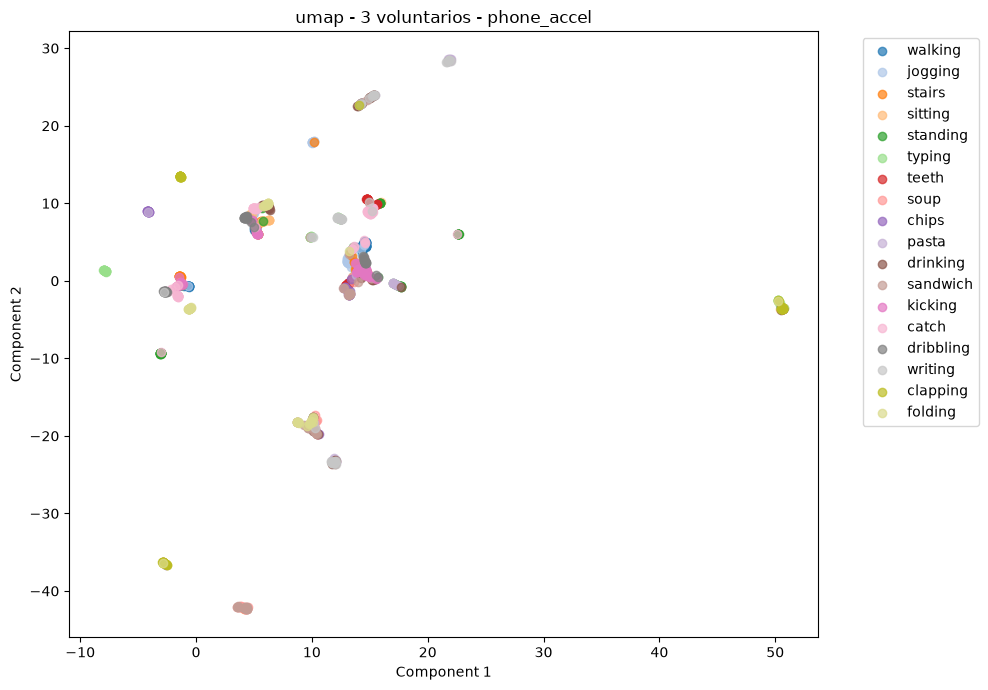


Caso combinado: phone_gyro
Datos: (965, 30)
  Ejecutando pca...


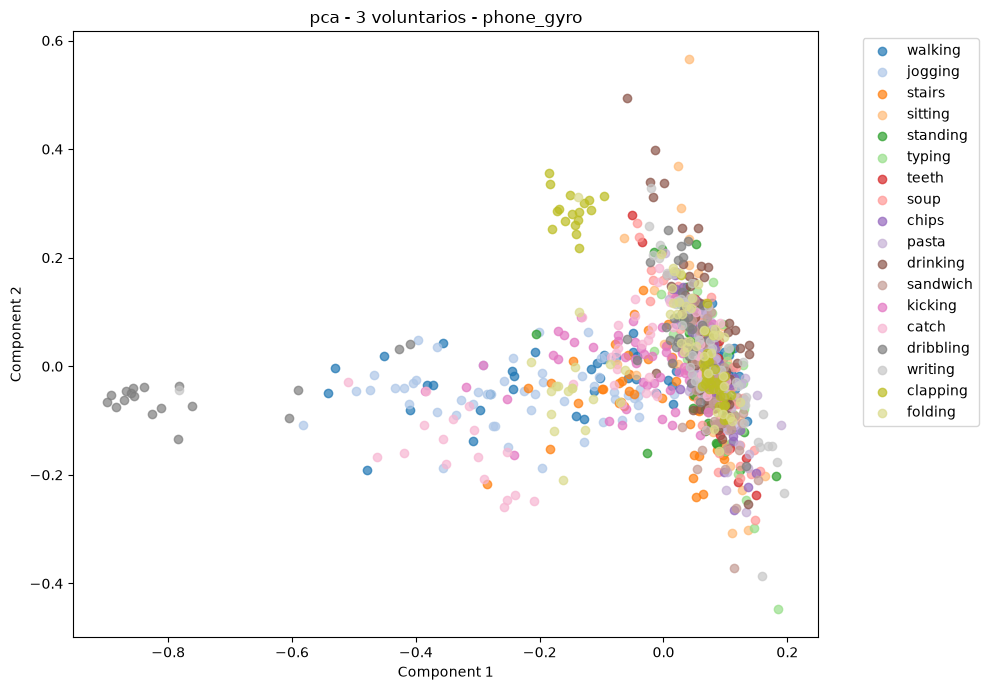

  Ejecutando classical_mds...


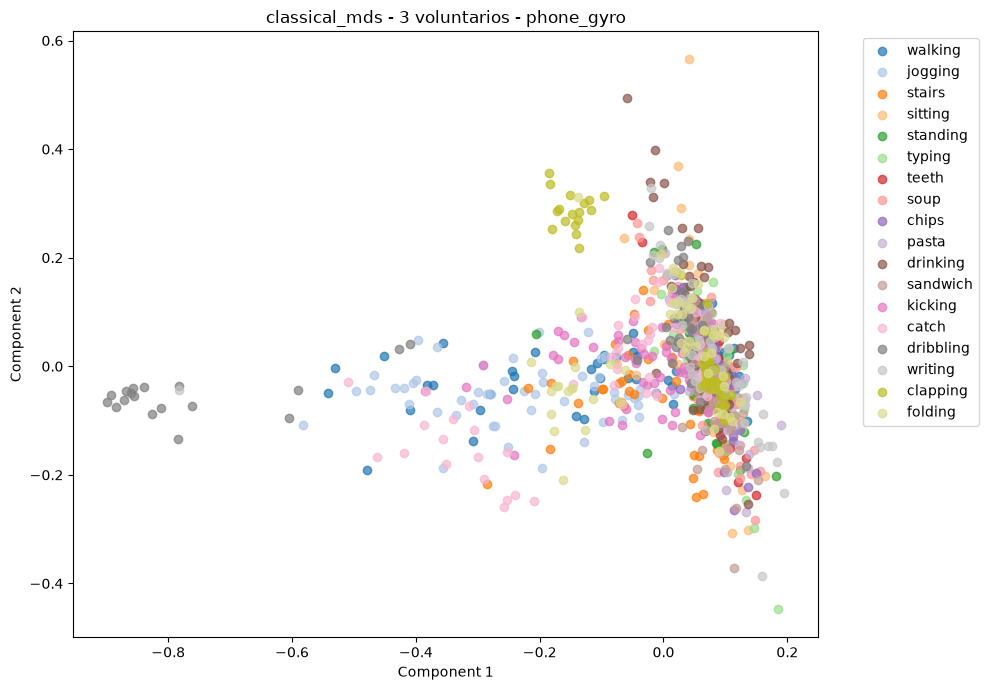

  Ejecutando metric_mds...


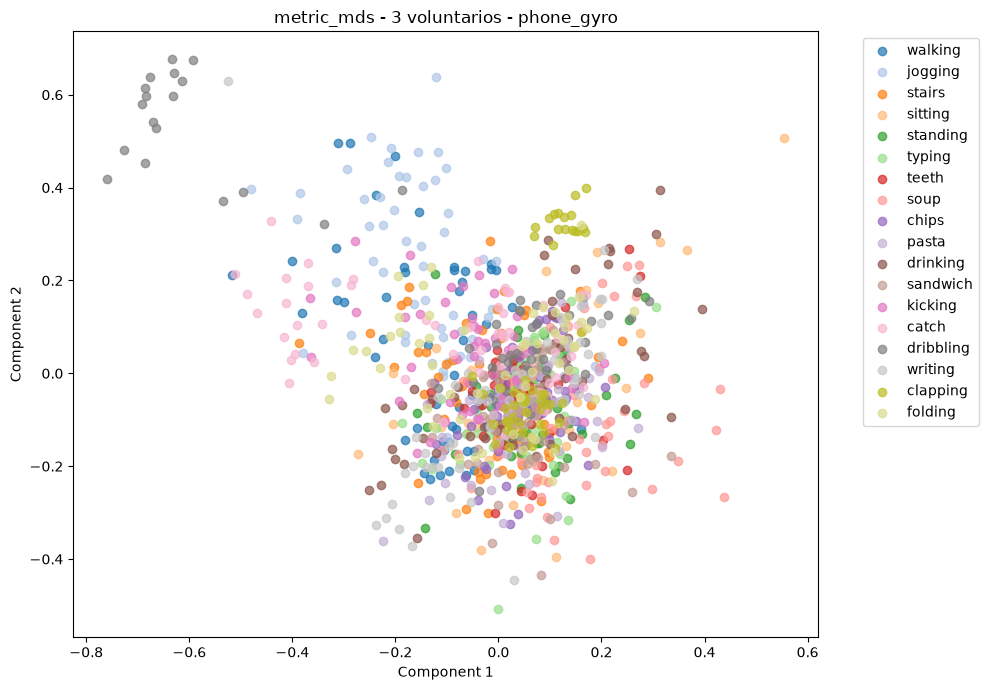

  Ejecutando nonmetric_mds...


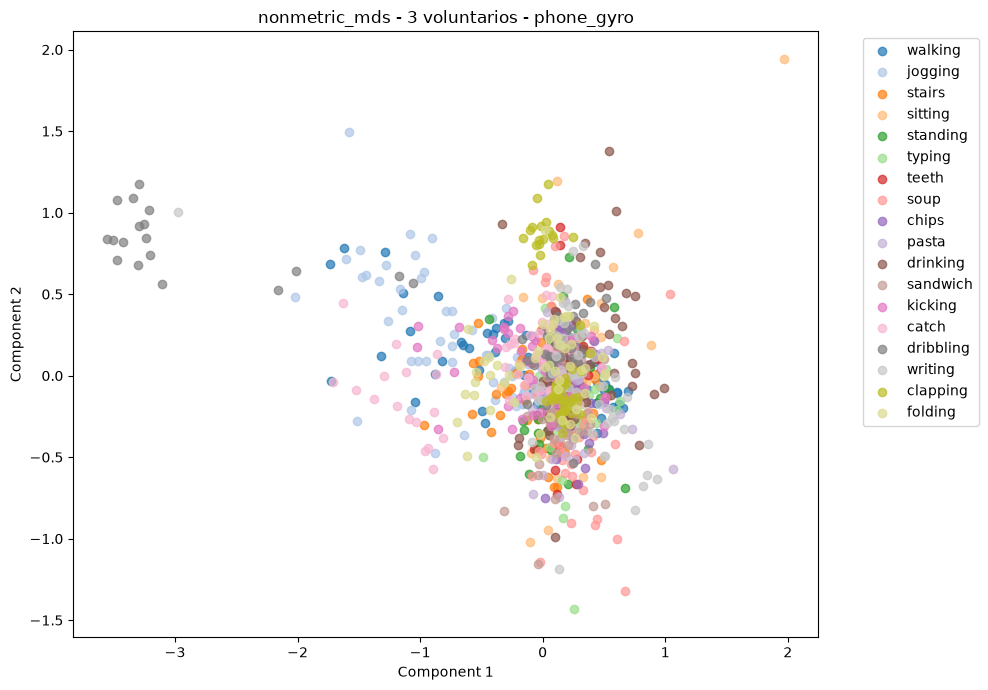

  Ejecutando umap...


/Users/franche/coding/Talleres_IA/Taller_06-Reducción/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


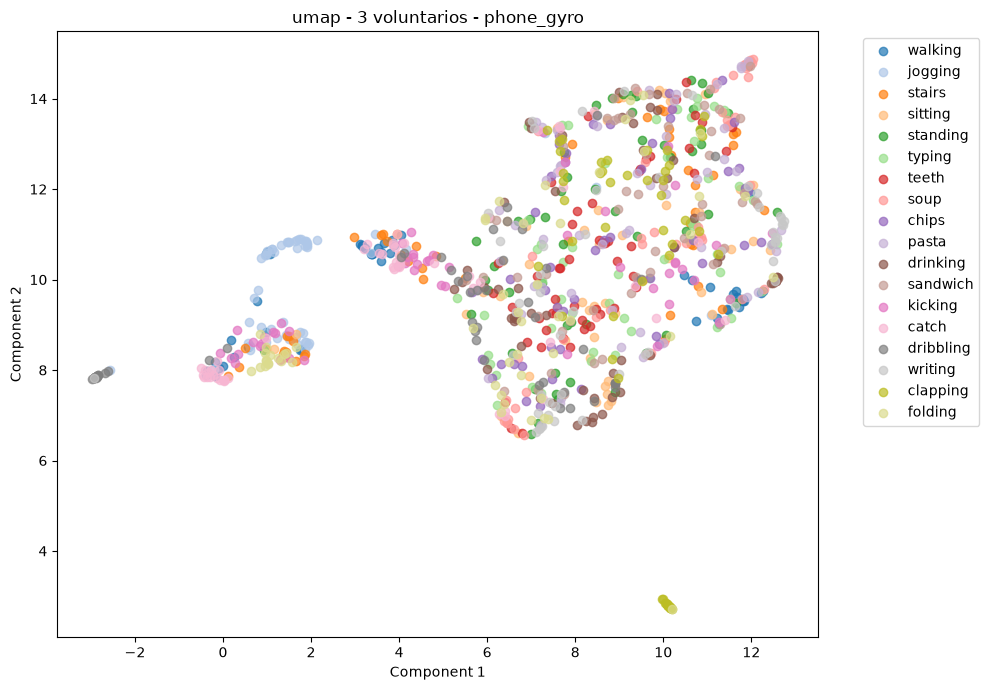


Caso combinado: watch_accel
Datos: (1451, 30)
  Ejecutando pca...


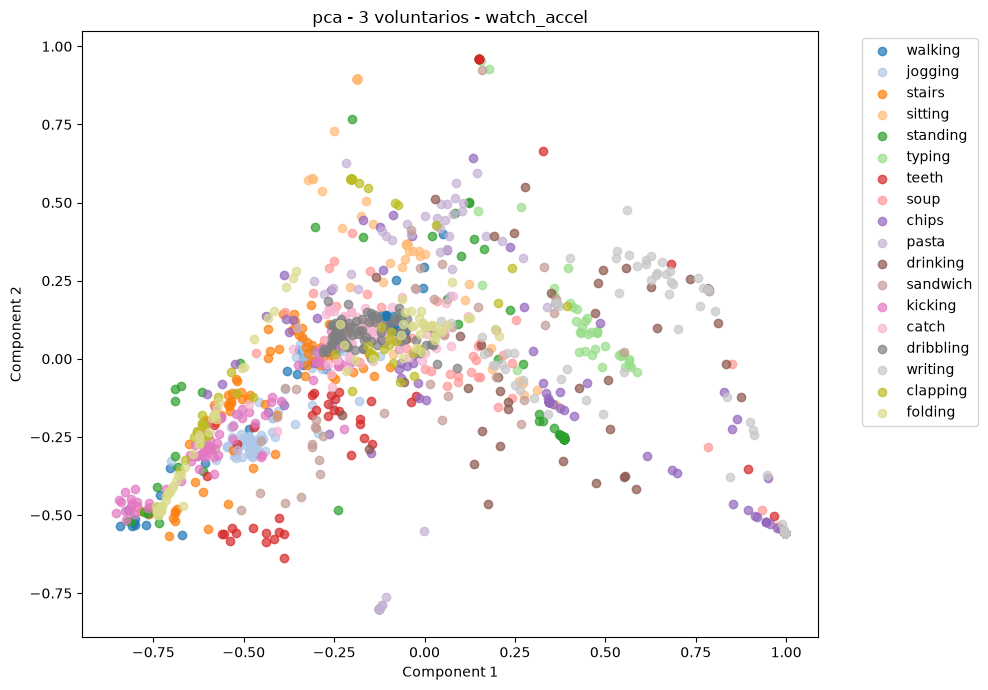

  Ejecutando classical_mds...


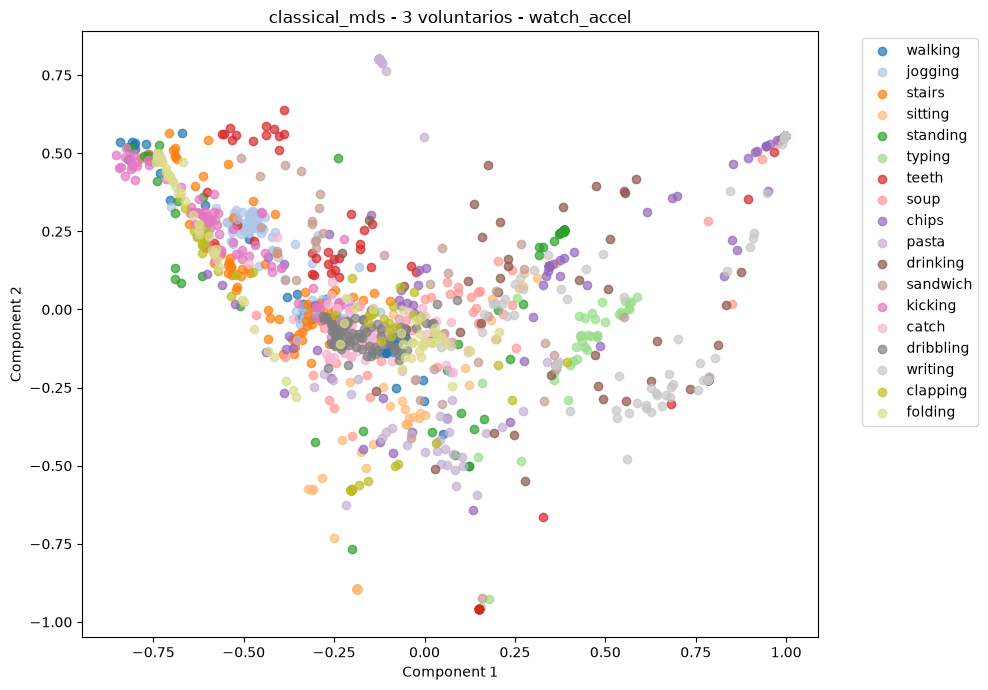

  Ejecutando metric_mds...


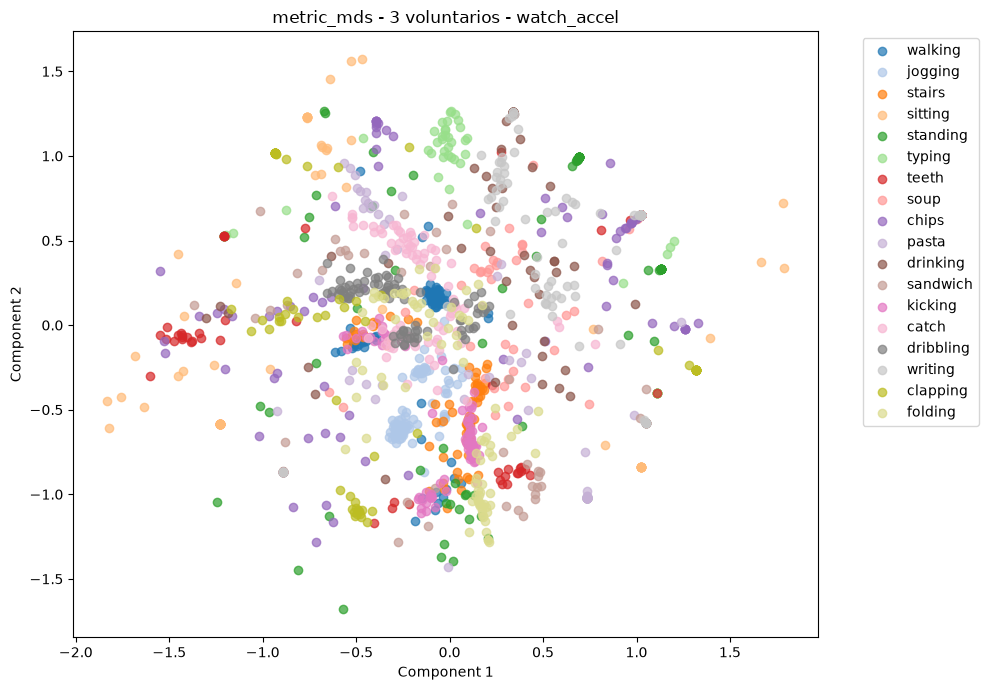

  Ejecutando nonmetric_mds...


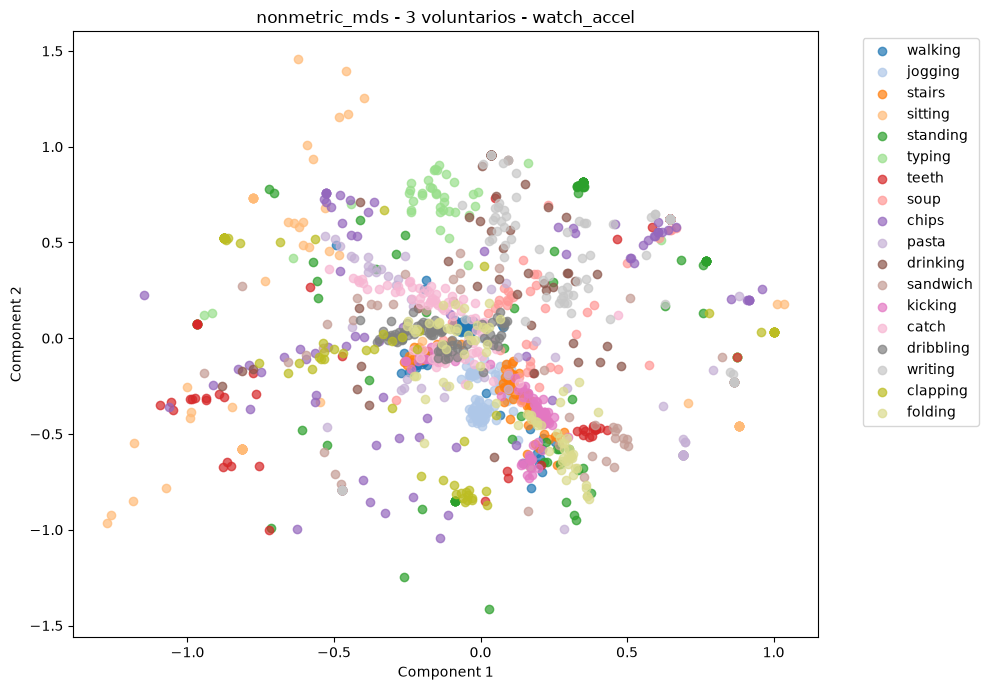

  Ejecutando umap...


/Users/franche/coding/Talleres_IA/Taller_06-Reducción/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


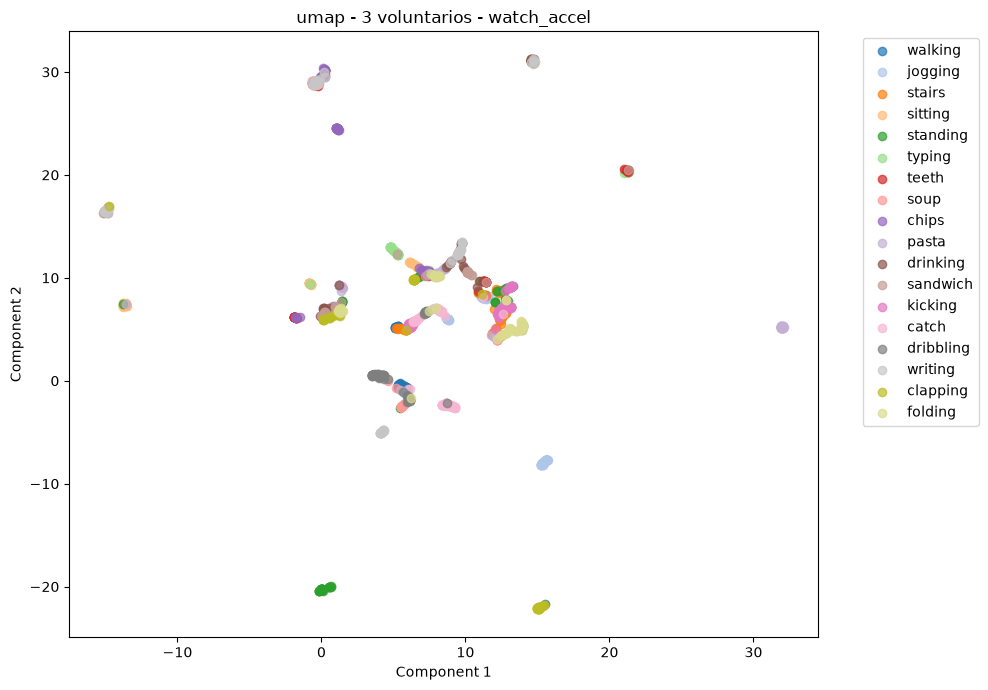


Caso combinado: watch_gyro
Datos: (1005, 30)
  Ejecutando pca...


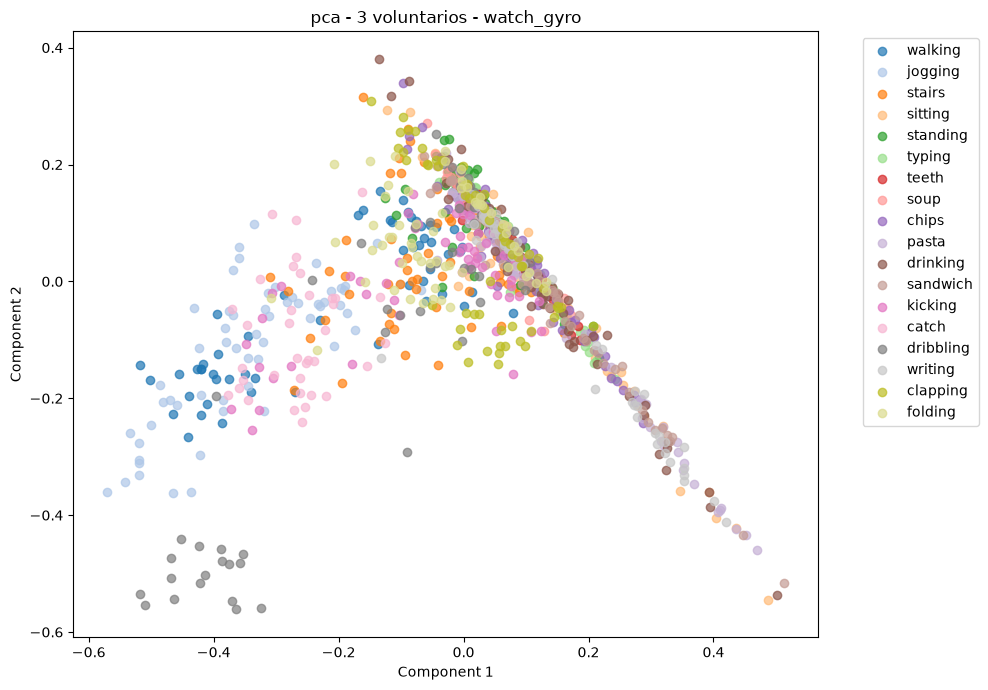

  Ejecutando classical_mds...


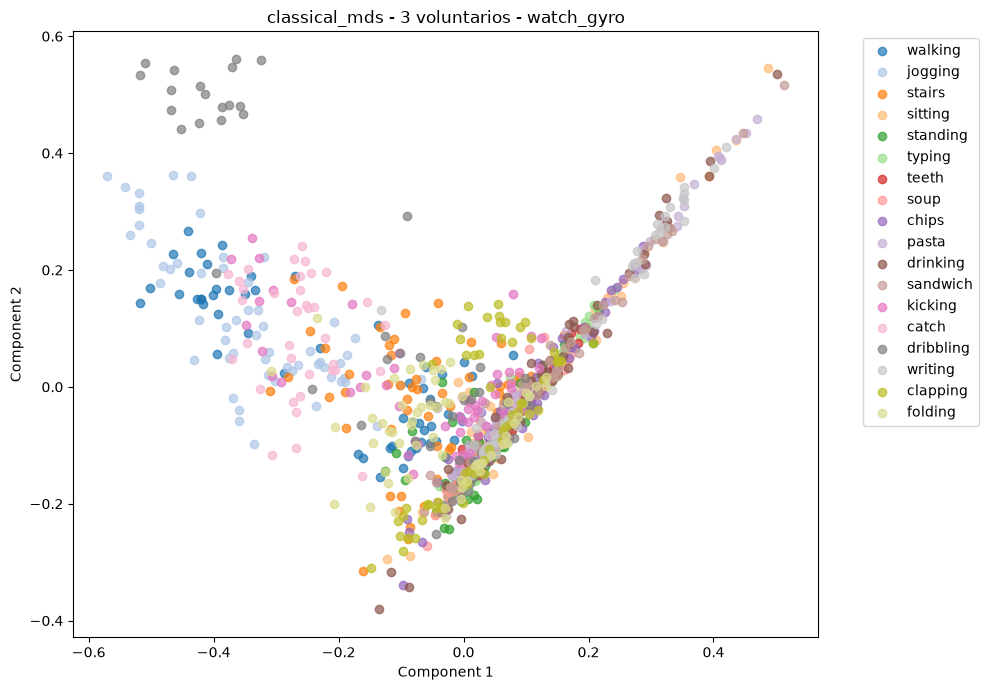

  Ejecutando metric_mds...


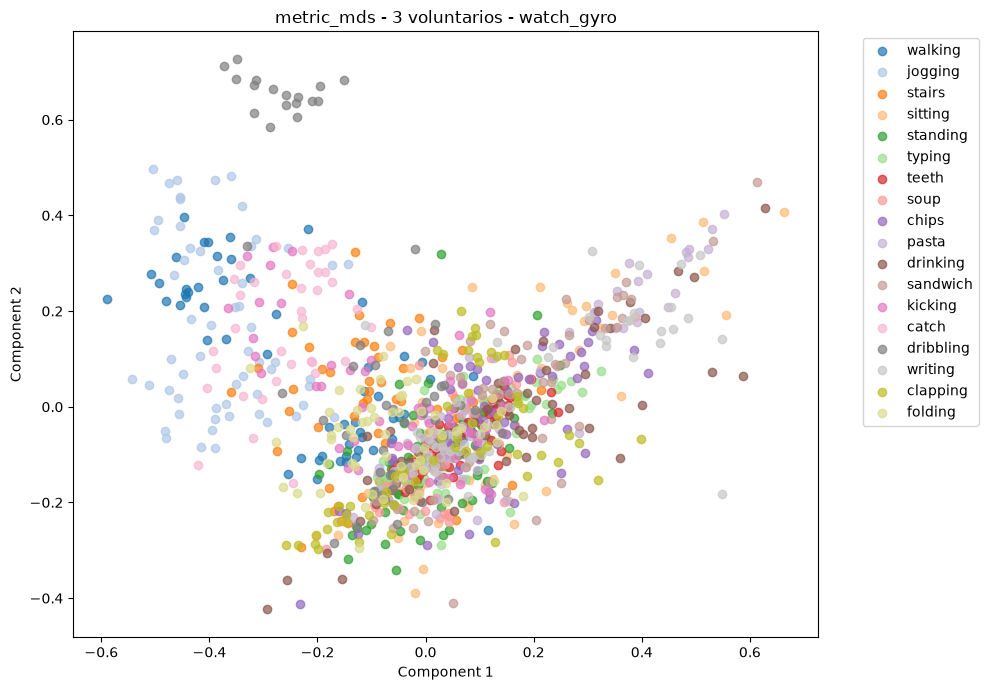

  Ejecutando nonmetric_mds...


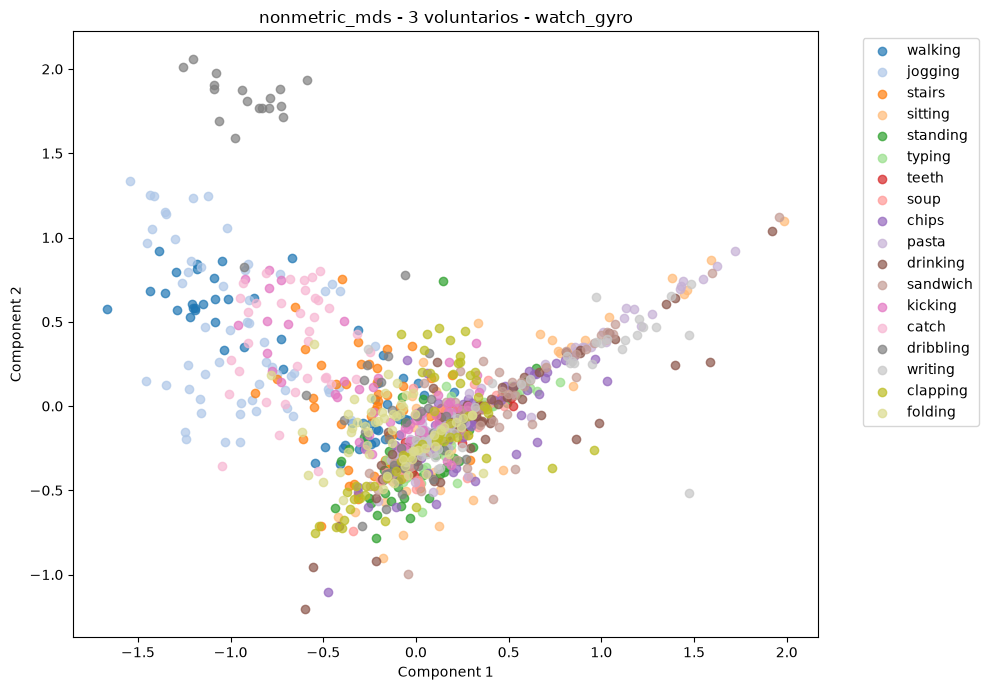

  Ejecutando umap...


/Users/franche/coding/Talleres_IA/Taller_06-Reducción/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


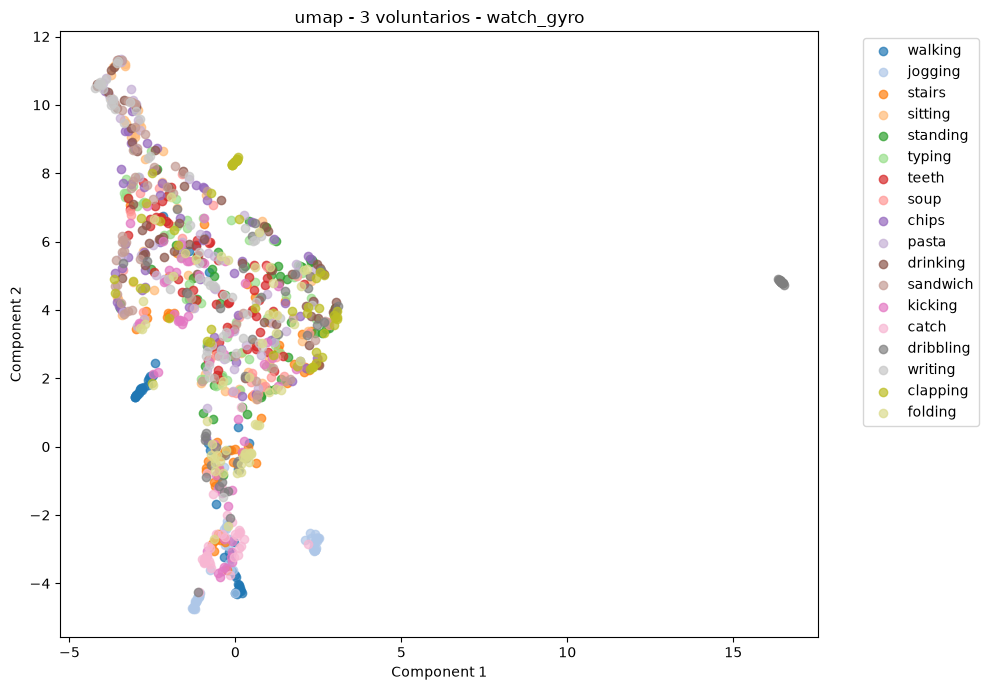

In [57]:
all_combined_results = {}

for case_name in cases:
    all_combined_results[case_name] = analyze_combined(case_name)

## 6. Evaluación

In [59]:
individual_silhouette = []

for subject_id in selected_subjects:
    for case_name in cases:

        X, y = prepare_subject(
            subject_id,
            *cases[case_name]
        )

        labels = y.map(activity_map)

        for method in methods:

            X_reduced = all_individual_results[
                subject_id
            ][case_name][method]["X_reduced"]

            score = silhouette_score(
                X_reduced,
                labels
            )

            individual_silhouette.append({
                "subject": subject_id,
                "case": case_name,
                "method": method,
                "silhouette": score
            })

individual_silhouette = pd.DataFrame(
    individual_silhouette
)

individual_silhouette

,subject,case,method,silhouette
0,1633,phone_accel,pca,-0.041787
1,1633,phone_accel,classical_mds,-0.041787
2,1633,phone_accel,metric_mds,0.021656
3,1633,phone_accel,nonmetric_mds,0.026258
4,1633,phone_accel,umap,0.061834
5,1633,phone_gyro,pca,-0.174958
6,1633,phone_gyro,classical_mds,-0.174958
7,1633,phone_gyro,metric_mds,-0.178032
8,1633,phone_gyro,nonmetric_mds,-0.186247
9,1633,phone_gyro,umap,-0.149379


In [60]:
combined_silhouette = []

for case_name in cases:

    X, y = combine_subjects(case_name)

    labels = y.map(activity_map)

    for method in methods:

        X_reduced = all_combined_results[
            case_name
        ][method]["X_reduced"]

        score = silhouette_score(
            X_reduced,
            labels
        )

        combined_silhouette.append({
            "case": case_name,
            "method": method,
            "silhouette": score
        })

combined_silhouette = pd.DataFrame(
    combined_silhouette
)

combined_silhouette

,case,method,silhouette
0,phone_accel,pca,-0.179889
1,phone_accel,classical_mds,-0.179889
2,phone_accel,metric_mds,-0.168174
3,phone_accel,nonmetric_mds,-0.186358
4,phone_accel,umap,-0.225922
5,phone_gyro,pca,-0.219089
6,phone_gyro,classical_mds,-0.219089
7,phone_gyro,metric_mds,-0.189735
8,phone_gyro,nonmetric_mds,-0.218130
9,phone_gyro,umap,-0.189807


In [61]:
combined_silhouette.sort_values(
    "silhouette",
    ascending=False
)

,case,method,silhouette
14,watch_accel,umap,-0.108031
2,phone_accel,metric_mds,-0.168174
12,watch_accel,metric_mds,-0.169402
11,watch_accel,classical_mds,-0.178584
10,watch_accel,pca,-0.178584
13,watch_accel,nonmetric_mds,-0.178738
1,phone_accel,classical_mds,-0.179889
0,phone_accel,pca,-0.179889
3,phone_accel,nonmetric_mds,-0.186358
7,phone_gyro,metric_mds,-0.189735


In [66]:
activity_silhouette = []

for case_name in cases:

    X, y = combine_subjects(case_name)
    labels = y.map(activity_map)

    for method in methods:

        X_reduced = all_combined_results[
            case_name
        ][method]["X_reduced"]

        sample_scores = silhouette_samples(
            X_reduced,
            labels
        )

        temp = pd.DataFrame({
            "activity": labels.values,
            "silhouette": sample_scores
        })

        grouped = (
            temp
            .groupby("activity")["silhouette"]
            .mean()
            .reset_index()
        )

        grouped["case"] = case_name
        grouped["method"] = method

        activity_silhouette.append(grouped)

activity_silhouette = pd.concat(
    activity_silhouette,
    ignore_index=True
)

activity_silhouette

,activity,silhouette,case,method
0,catch,-0.149718,phone_accel,pca
1,chips,-0.190901,phone_accel,pca
2,clapping,-0.062572,phone_accel,pca
3,dribbling,-0.223908,phone_accel,pca
4,drinking,-0.249154,phone_accel,pca
...,...,...,...,...
355,standing,-0.115393,watch_gyro,umap
356,teeth,0.026179,watch_gyro,umap
357,typing,-0.173519,watch_gyro,umap
358,walking,-0.324343,watch_gyro,umap


In [72]:
comparison = combined_silhouette.pivot(
    index="case",
    columns="method",
    values="silhouette"
)

comparison

method,classical_mds,metric_mds,nonmetric_mds,pca,umap
case,,,,,
phone_accel,-0.179889,-0.168174,-0.186358,-0.179889,-0.225922
phone_gyro,-0.219089,-0.189735,-0.218130,-0.219089,-0.189807
watch_accel,-0.178584,-0.169402,-0.178738,-0.178584,-0.108031
watch_gyro,-0.264944,-0.232369,-0.265692,-0.264944,-0.200153


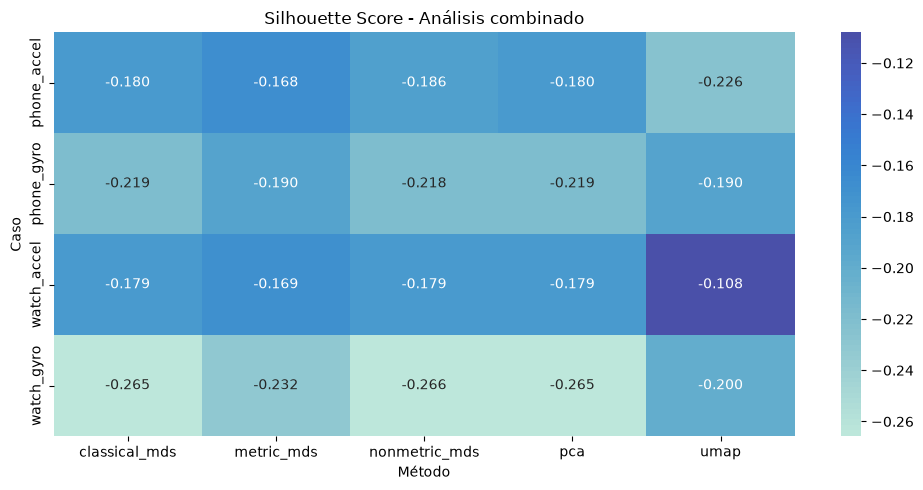

In [73]:
plt.figure(figsize=(10, 5))

sns.heatmap(
    comparison,
    annot=True,
    fmt=".3f",
    center=0
)

plt.title("Silhouette Score - Análisis combinado")
plt.xlabel("Método")
plt.ylabel("Caso")

plt.tight_layout()
plt.show()

In [74]:
individual_mean = (
    individual_silhouette
    .groupby(["case", "method"])["silhouette"]
    .mean()
    .reset_index()
)

individual_mean

,case,method,silhouette
0,phone_accel,classical_mds,0.012128
1,phone_accel,metric_mds,0.045041
2,phone_accel,nonmetric_mds,0.066394
3,phone_accel,pca,0.012128
4,phone_accel,umap,0.163945
5,phone_gyro,classical_mds,-0.177359
6,phone_gyro,metric_mds,-0.162795
7,phone_gyro,nonmetric_mds,-0.176674
8,phone_gyro,pca,-0.177359
9,phone_gyro,umap,-0.118386


In [75]:
comparison_individual_combined = individual_mean.merge(
    combined_silhouette,
    on=["case", "method"],
    suffixes=("_individual", "_combined")
)

comparison_individual_combined["change"] = (
    comparison_individual_combined["silhouette_combined"]
    - comparison_individual_combined["silhouette_individual"]
)

comparison_individual_combined.sort_values(
    "change",
    ascending=False
)

,case,method,silhouette_individual,silhouette_combined,change
6,phone_gyro,metric_mds,-0.162795,-0.189735,-0.026940
7,phone_gyro,nonmetric_mds,-0.176674,-0.218130,-0.041456
5,phone_gyro,classical_mds,-0.177359,-0.219089,-0.041729
8,phone_gyro,pca,-0.177359,-0.219089,-0.041729
9,phone_gyro,umap,-0.118386,-0.189807,-0.071421
16,watch_gyro,metric_mds,-0.113403,-0.232369,-0.118966
18,watch_gyro,pca,-0.129925,-0.264944,-0.135019
15,watch_gyro,classical_mds,-0.129925,-0.264944,-0.135019
17,watch_gyro,nonmetric_mds,-0.126220,-0.265692,-0.139472
19,watch_gyro,umap,-0.050039,-0.200153,-0.150114


In [77]:
best_methods = (
    combined_silhouette
    .loc[
        combined_silhouette
        .groupby("case")["silhouette"]
        .idxmax()
    ]
)

best_methods

,case,method,silhouette
2,phone_accel,metric_mds,-0.168174
7,phone_gyro,metric_mds,-0.189735
14,watch_accel,umap,-0.108031
19,watch_gyro,umap,-0.200153


In [78]:
pairwise_overlap = []

for _, row in best_methods.iterrows():

    case_name = row["case"]
    method = row["method"]

    X, y = combine_subjects(case_name)
    labels = y.map(activity_map)

    X_reduced = all_combined_results[
        case_name
    ][method]["X_reduced"]

    temp = pd.DataFrame({
        "activity": labels.values,
        "x": X_reduced[:, 0],
        "y": X_reduced[:, 1]
    })

    centroids = (
        temp
        .groupby("activity")[["x", "y"]]
        .mean()
    )

    for activity_1, activity_2 in combinations(
        centroids.index, 2
    ):

        centroid_1 = centroids.loc[activity_1].values
        centroid_2 = centroids.loc[activity_2].values

        distance = np.linalg.norm(
            centroid_1 - centroid_2
        )

        pairwise_overlap.append({
            "case": case_name,
            "method": method,
            "activity_1": activity_1,
            "activity_2": activity_2,
            "centroid_distance": distance
        })

pairwise_overlap = pd.DataFrame(pairwise_overlap)

In [80]:
for case_name in pairwise_overlap["case"].unique():
    print(f"\n{'=' * 60}")
    print(f"CASO: {case_name}")
    print(f"{'=' * 60}")

    display(
        pairwise_overlap[
            pairwise_overlap["case"] == case_name
        ]
        .sort_values("centroid_distance")
        .head(10)
    )



CASO: phone_accel


,case,method,activity_1,activity_2,centroid_distance
60,phone_accel,metric_mds,dribbling,walking,0.013544
91,phone_accel,metric_mds,jogging,soup,0.016672
22,phone_accel,metric_mds,chips,kicking,0.048212
110,phone_accel,metric_mds,pasta,soup,0.072139
88,phone_accel,metric_mds,jogging,pasta,0.078401
16,phone_accel,metric_mds,catch,writing,0.080315
105,phone_accel,metric_mds,kicking,typing,0.088164
65,phone_accel,metric_mds,drinking,pasta,0.097371
120,phone_accel,metric_mds,sandwich,standing,0.099931
30,phone_accel,metric_mds,chips,typing,0.109287



CASO: phone_gyro


,case,method,activity_1,activity_2,centroid_distance
261,phone_gyro,metric_mds,pasta,sandwich,0.013980
267,phone_gyro,metric_mds,pasta,typing,0.014295
182,phone_gyro,metric_mds,chips,teeth,0.015222
183,phone_gyro,metric_mds,chips,typing,0.018236
220,phone_gyro,metric_mds,drinking,sitting,0.019054
181,phone_gyro,metric_mds,chips,standing,0.020108
203,phone_gyro,metric_mds,dribbling,jogging,0.021169
275,phone_gyro,metric_mds,sandwich,typing,0.025752
281,phone_gyro,metric_mds,sitting,teeth,0.027722
295,phone_gyro,metric_mds,stairs,writing,0.027914



CASO: watch_accel


,case,method,activity_1,activity_2,centroid_distance
408,watch_accel,umap,kicking,stairs,1.131569
387,watch_accel,umap,folding,stairs,1.434981
321,watch_accel,umap,catch,walking,1.443761
332,watch_accel,umap,chips,soup,1.690128
366,watch_accel,umap,dribbling,walking,1.703631
382,watch_accel,umap,folding,kicking,1.768098
443,watch_accel,umap,soup,writing,1.895084
335,watch_accel,umap,chips,teeth,1.962347
440,watch_accel,umap,soup,teeth,2.713186
308,watch_accel,umap,catch,dribbling,3.030602



CASO: watch_gyro


,case,method,activity_1,activity_2,centroid_distance
575,watch_gyro,umap,pasta,writing,0.192041
606,watch_gyro,umap,teeth,typing,0.222443
484,watch_gyro,umap,chips,sitting,0.231593
483,watch_gyro,umap,chips,sandwich,0.365544
583,watch_gyro,umap,sandwich,writing,0.469298
491,watch_gyro,umap,chips,writing,0.518942
533,watch_gyro,umap,drinking,writing,0.556721
592,watch_gyro,umap,soup,standing,0.585379
576,watch_gyro,umap,sandwich,sitting,0.595311
524,watch_gyro,umap,drinking,pasta,0.599211


In [81]:
activity_dispersion = []

for _, row in best_methods.iterrows():

    case_name = row["case"]
    method = row["method"]

    X, y = combine_subjects(case_name)
    labels = y.map(activity_map)

    X_reduced = all_combined_results[
        case_name
    ][method]["X_reduced"]

    temp = pd.DataFrame({
        "activity": labels.values,
        "x": X_reduced[:, 0],
        "y": X_reduced[:, 1]
    })

    for activity, group in temp.groupby("activity"):

        points = group[["x", "y"]].values
        centroid = points.mean(axis=0)

        distances = np.linalg.norm(
            points - centroid,
            axis=1
        )

        activity_dispersion.append({
            "case": case_name,
            "method": method,
            "activity": activity,
            "mean_distance_to_centroid": distances.mean()
        })

activity_dispersion = pd.DataFrame(
    activity_dispersion
)

In [85]:
# Resumen de los mejores métodos por caso

best_combined = (
    combined_silhouette
    .loc[
        combined_silhouette
        .groupby("case")["silhouette"]
        .idxmax()
    ]
    .sort_values("silhouette", ascending=False)
)

best_combined

,case,method,silhouette
14,watch_accel,umap,-0.108031
2,phone_accel,metric_mds,-0.168174
7,phone_gyro,metric_mds,-0.189735
19,watch_gyro,umap,-0.200153


In [86]:
# Mejor método promedio para cada caso en los análisis individuales

best_individual = (
    individual_mean
    .loc[
        individual_mean
        .groupby("case")["silhouette"]
        .idxmax()
    ]
    .sort_values("silhouette", ascending=False)
)

best_individual

,case,method,silhouette
14,watch_accel,umap,0.412305
4,phone_accel,umap,0.163945
19,watch_gyro,umap,-0.050039
9,phone_gyro,umap,-0.118386


In [87]:
activity_summary = (
    activity_silhouette
    .groupby("activity")["silhouette"]
    .agg(["mean", "max", "min"])
    .sort_values("mean", ascending=False)
)

activity_summary

,mean,max,min
activity,,,
jogging,0.102104,0.445220,-0.109972
catch,-0.072365,0.397798,-0.395462
soup,-0.158054,0.186654,-0.413191
teeth,-0.165370,0.222176,-0.543223
typing,-0.193420,0.171391,-0.418604
drinking,-0.202335,0.095230,-0.430200
kicking,-0.205189,0.046966,-0.454089
stairs,-0.218916,0.033445,-0.474677
standing,-0.223445,-0.115393,-0.489084


## 7. Comparación de resultados

### Separación de actividades

El análisis mediante Silhouette Score muestra que el comportamiento de las actividades depende tanto del sensor utilizado como del método de reducción dimensional.

En los análisis individuales, UMAP obtuvo el mejor resultado promedio para los cuatro tipos de datos. El mejor resultado se obtuvo con el acelerómetro del reloj (`watch_accel`), alcanzando un Silhouette Score de 0.4123.

Al combinar los tres voluntarios, todos los resultados obtuvieron valores negativos. El mejor resultado correspondió nuevamente al acelerómetro del reloj utilizando UMAP, con un Silhouette Score de -0.1080. Aunque este fue el mejor resultado relativo, el valor negativo indica que existe un solapamiento considerable entre las actividades.

La comparación entre los análisis individuales y combinados evidencia una disminución importante en la separación de las actividades al incorporar diferentes voluntarios. Esto sugiere la existencia de variabilidad inter-sujeto en los patrones registrados por los sensores.

En cuanto a las actividades, `jogging` presentó la mejor separación promedio, con un Silhouette Score de 0.1021, y alcanzó un máximo de 0.4452 utilizando el giroscopio del teléfono y UMAP. Por el contrario, `writing`, `walking` y `folding` presentaron los valores promedio más bajos, indicando una mayor dificultad para separarlas en el espacio bidimensional.

## 8. Conclusiones

En este trabajo se aplicaron PCA, Classical MDS, Metric MDS, Non-metric MDS y UMAP a las características xyzbins de los acelerómetros y giroscopios del teléfono y del reloj inteligente.

En general, UMAP presentó el mejor comportamiento en los análisis individuales, especialmente para el acelerómetro del reloj. Sin embargo, al combinar los tres voluntarios se observó un deterioro significativo de la separación entre actividades, obteniéndose valores negativos de Silhouette en todos los casos.

La actividad que presentó la mejor separación promedio fue `jogging`, mientras que `writing`, `walking` y `folding` mostraron mayor dificultad de separación. Los resultados muestran que la reducción dimensional permite visualizar diferencias entre actividades, pero también evidencian una importante variabilidad entre voluntarios.

El acelerómetro del reloj fue el tipo de sensor que produjo las representaciones más favorables, particularmente mediante UMAP. No obstante, la separación no se mantiene completamente cuando se combinan diferentes voluntarios, lo que indica que los patrones de actividad dependen en cierta medida de las características individuales de cada sujeto.## 9. Conclusiones